# AICS-202 Adversarial Machine Learning — Integrated Practical Assessment
## Step 1 — Setup: connect Drive and locate the package

In [2]:
# ==== 1. SETUP: connect Google Drive, point to the uploaded package, create output folders ====
import os, sys, json, platform, datetime, hashlib, shutil, subprocess, warnings
from pathlib import Path
import numpy as np, pandas as pd, sklearn, matplotlib
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_predict
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay, confusion_matrix, classification_report
warnings.filterwarnings('ignore')
try:
    import docx
except ImportError:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'python-docx'], check=True)

# ---------- EDIT THESE ----------
STUDENT_NAME  = 'Asim Shayan Khan'
REG_NO        = '2026/AICDF/16715'
COHORT        = 'AICDF-COHORT-2026-Q1'
GITHUB_URL    = '[paste your GitHub repository URL here]'
DRIVE_PROJECT = 'AICS202/ICDFA_AICS202_Complete_Student_Training_Package'   # folder path inside My Drive
ADDITIONAL_EPS = 0.15          # your own extra epsilon for Lab 02 (allowed range 0.01-0.20)
RUN_ORIGINAL_NOTEBOOKS = True  # also save executed copies of the 4 lab notebooks (needed for submission)
MAKE_PDF = True                # also convert the Word report to PDF (installs LibreOffice, ~2 min)
# --------------------------------

try:
    from google.colab import drive
    drive.mount('/content/drive')
    ROOT, IN_COLAB = Path('/content/drive/MyDrive'), True
except ImportError:                              # only used when testing outside Colab
    ROOT, IN_COLAB = Path(os.environ.get('LOCAL_ROOT', '.')).resolve(), False

BASE = ROOT / DRIVE_PROJECT
if not BASE.exists():
    raise FileNotFoundError(f'Package folder not found: {BASE}\nOpen the Files sidebar (folder icon), browse to the folder you uploaded, and correct DRIVE_PROJECT above.')
LABS_DIR = BASE / 'Labs'
LAB_FILES = {1: 'AICS202_Lab01_Baseline_Threat_Model.ipynb', 2: 'AICS202_Lab02_FGSM_Evasion.ipynb',
             3: 'AICS202_Lab03_Poisoning_Data_Integrity.ipynb', 4: 'AICS202_Lab04_Robustness_Defences.ipynb'}
RESULTS, SUB = BASE / 'Results', BASE / 'Submission'
for d in [RESULTS / s for s in ('figures', 'tables', 'evidence', 'logs')] + [SUB]:
    d.mkdir(parents=True, exist_ok=True)         # only NEW output folders are created; your uploaded folders are never modified
assert 0.01 <= ADDITIONAL_EPS <= 0.20, 'ADDITIONAL_EPS must be between 0.01 and 0.20'

def save_fig(name):
    p = RESULTS / 'figures' / f'{name}.png'
    plt.savefig(p, dpi=200, bbox_inches='tight'); return p

def run_lab_notebook(path):
    """Run the code cells of one of YOUR course notebooks (read from Drive) in this session."""
    nb = json.load(open(path, encoding='utf-8')); n = 0
    for c in nb['cells']:
        if c['cell_type'] == 'code' and ''.join(c['source']).strip():
            exec(compile(''.join(c['source']), path.name, 'exec'), globals()); n += 1
    print(f'--- ran {n} code cells from {path.name} ---')

ENV = {'run_date': datetime.datetime.now().strftime('%d %B %Y, %H:%M'), 'platform': 'Google Colab' if IN_COLAB else 'Local Python',
       'os': platform.platform(), 'python': sys.version.split()[0], 'numpy': np.__version__, 'scikit-learn': sklearn.__version__,
       'matplotlib': matplotlib.__version__, 'pandas': pd.__version__}
json.dump(ENV, open(RESULTS / 'logs' / 'environment.json', 'w'), indent=2)
R = {}      # every measured result is stored here; the report generator reads from it
print('Package folder:', BASE); print('Output folders ready:', sorted(p.name for p in BASE.iterdir() if p.is_dir()))
print(json.dumps(ENV, indent=2))


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Package folder: /content/drive/MyDrive/AICS202/ICDFA_AICS202_Complete_Student_Training_Package
Output folders ready: ['Lab_Companion', 'Labs', 'Manual', 'Results', 'Submission']
{
  "run_date": "18 November 2026, 16:13",
  "platform": "Google Colab",
  "os": "Linux-6.6.159+-x86_64-with-glibc2.39",
  "python": "3.13.18",
  "numpy": "2.4.6",
  "scikit-learn": "1.6.1",
  "matplotlib": "3.10.0",
  "pandas": "2.2.3"
}


In [3]:
# ==== 1B. CHECK THE PACKAGE YOU UPLOADED (reads only - nothing in your folders is changed) ====
from importlib import metadata
from packaging.requirements import Requirement
from docx import Document

manual_docs = sorted((BASE / 'Manual').glob('*.docx')); handbook_docs = sorted((BASE / 'Lab_Companion').glob('*.docx'))
checks = [(f'Labs/{f}', (LABS_DIR / f).exists()) for f in LAB_FILES.values()]
checks += [('Labs/README.md', (LABS_DIR / 'README.md').exists()), ('Labs/requirements.txt', (LABS_DIR / 'requirements.txt').exists()),
           ('START_HERE.txt', (BASE / 'START_HERE.txt').exists()), ('Manual/*.docx', bool(manual_docs)), ('Lab_Companion/*.docx or .pdf', bool(handbook_docs) or bool(list((BASE / 'Lab_Companion').glob('*.pdf'))))]
print(pd.DataFrame([(n, 'OK' if ok else 'MISSING') for n, ok in checks], columns=['Expected item', 'Status']).to_string(index=False))
missing_labs = [n for n, ok in checks if n.startswith('Labs/AICS202') and not ok]
if missing_labs: raise FileNotFoundError(f'Lab notebooks missing from {LABS_DIR}: {missing_labs}')

if (BASE / 'START_HERE.txt').exists():
    print('\n----- START_HERE.txt (safety rules apply to every step below) -----')
    print((BASE / 'START_HERE.txt').read_text(encoding='utf-8', errors='ignore'))

print('\n----- requirements.txt versus this Colab session -----')
for line in (LABS_DIR / 'requirements.txt').read_text().splitlines():
    if line.strip() and not line.startswith('#'):
        req = Requirement(line.strip())
        try: v = metadata.version(req.name); ok = req.specifier.contains(v, prereleases=True)
        except metadata.PackageNotFoundError: v, ok = 'not installed', False
        print(f'{line.strip():<18} installed: {v:<14} {"OK" if ok else "differs (not needed in Colab)" if req.name == "notebook" else "CHECK"}')

outline = []
for label, files in (('MANUAL', manual_docs), ('LAB HANDBOOK', handbook_docs)):
    for f in files:
        outline.append(f'== {label}: {f.name}')
        outline += [f'   {p.text}' for p in Document(f).paragraphs if p.style.name == 'Heading 1']
(RESULTS / 'logs' / 'course_outline.txt').write_text('\n'.join(outline), encoding='utf-8')
print('\n----- Course documents found (main headings) -----'); print('\n'.join(outline) if outline else 'No .docx course documents found (PDF copies are fine).')


                                    Expected item Status
   Labs/AICS202_Lab01_Baseline_Threat_Model.ipynb     OK
            Labs/AICS202_Lab02_FGSM_Evasion.ipynb     OK
Labs/AICS202_Lab03_Poisoning_Data_Integrity.ipynb     OK
     Labs/AICS202_Lab04_Robustness_Defences.ipynb     OK
                                   Labs/README.md     OK
                            Labs/requirements.txt     OK
                                   START_HERE.txt     OK
                                    Manual/*.docx     OK
                     Lab_Companion/*.docx or .pdf     OK

----- START_HERE.txt (safety rules apply to every step below) -----
ICDFA - AICS-202 Adversarial Machine Learning
STUDENT PRACTICAL LEARNING PACKAGE
Version 1.0 | October 2026

CONTENTS
1. Manual/ICDFA_AICS202_Comprehensive_Practical_Training_Manual.pdf
2. Manual/ICDFA_AICS202_Comprehensive_Practical_Training_Manual.docx
3. Labs/AICS202_Lab01_Baseline_Threat_Model.ipynb
4. Labs/AICS202_Lab02_FGSM_Evasion.ipynb
5. Labs/AICS202

# Lab 01: Baseline model and threat model

Dataset: (1797, 64) | Train: 1347 | Test: 450
Clean test accuracy: 0.9622


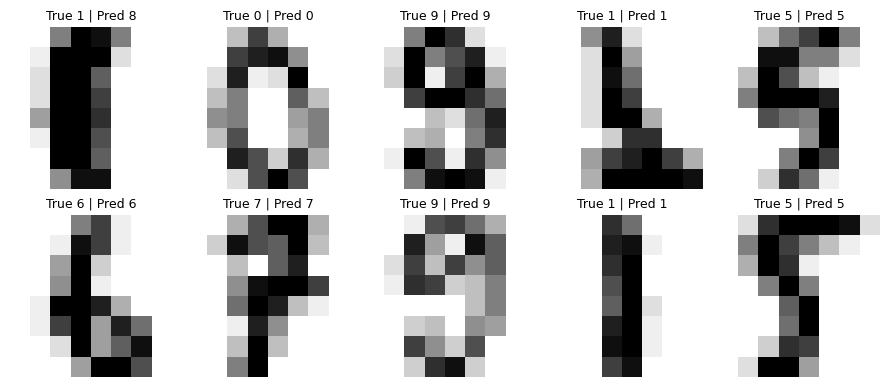

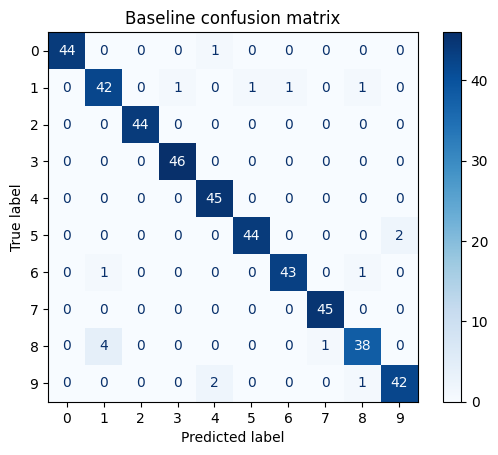

--- ran 2 code cells from AICS202_Lab01_Baseline_Threat_Model.ipynb ---


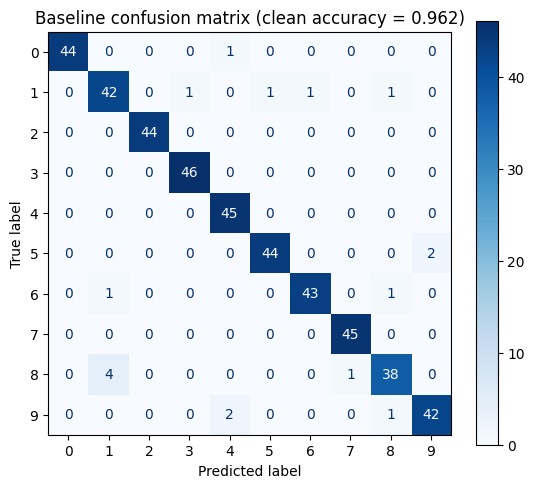

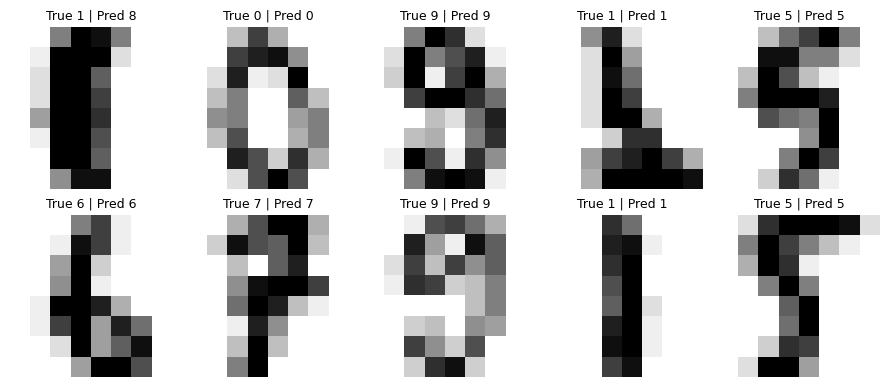

                     Item                            Value
                  Dataset              sklearn load_digits
                  Samples                             1797
                 Features                               64
                  Classes                               10
Pixel range (raw -> used)      0-16 -> 0-1 (divided by 16)
               Train size                             1347
                Test size                              450
                    Split                 75/25 stratified
              Random seed                               42
                    Model LogisticRegression(max_iter=600)
      Clean test accuracy                           0.9622

Most frequent confusions:
 true  predicted  count
    8          1      4
    5          9      2
    9          4      2
    0          4      1
    1          3      1


In [4]:
# ==== 2. LAB 01: BASELINE MODEL AND THREAT MODEL ====
run_lab_notebook(LABS_DIR / LAB_FILES[1])          # the course notebook's own code, read from your Drive folder
assert 'model' in globals() and 'X_test' in globals(), 'Lab 01 notebook did not define the baseline model'

# --- evidence: save everything the report needs (the lab cells only display it) ---
pred = model.predict(X_test); clean_acc = accuracy_score(y_test, pred)
fig, ax = plt.subplots(figsize=(6.5, 5.5))
ConfusionMatrixDisplay.from_estimator(model, X_test, y_test, cmap='Blues', ax=ax)
ax.set_title(f'Baseline confusion matrix (clean accuracy = {clean_acc:.3f})'); save_fig('lab01_confusion_matrix'); plt.show()
fig, axes = plt.subplots(2, 5, figsize=(9, 4))
for ax, i in zip(axes.ravel(), range(10)):
    ax.imshow(X_test[i].reshape(8, 8), cmap='gray_r', vmin=0, vmax=1)
    ax.set_title(f'True {y_test[i]} | Pred {pred[i]}', fontsize=9); ax.axis('off')
plt.tight_layout(); save_fig('lab01_samples'); plt.show()
cm = confusion_matrix(y_test, pred)
off = [(i, j, int(cm[i, j])) for i in range(10) for j in range(10) if i != j and cm[i, j] > 0]
top_conf = pd.DataFrame(sorted(off, key=lambda t: -t[2]), columns=['true', 'predicted', 'count']).head(5)
per_class = pd.DataFrame(classification_report(y_test, pred, output_dict=True)).T.round(3)
summary = pd.DataFrame({'Item': ['Dataset', 'Samples', 'Features', 'Classes', 'Pixel range (raw -> used)', 'Train size', 'Test size', 'Split', 'Random seed', 'Model', 'Clean test accuracy'],
                        'Value': ['sklearn load_digits', X.shape[0], X.shape[1], 10, '0-16 -> 0-1 (divided by 16)', len(X_train), len(X_test), '75/25 stratified', SEED, 'LogisticRegression(max_iter=600)', round(clean_acc, 4)]})
summary.to_csv(RESULTS / 'tables' / 'lab01_dataset_summary.csv', index=False); top_conf.to_csv(RESULTS / 'tables' / 'lab01_top_confusions.csv', index=False)
per_class.to_csv(RESULTS / 'tables' / 'lab01_per_class_report.csv')
pc_f1 = per_class.iloc[:10]['f1-score'].astype(float)
R['lab01'] = dict(acc=clean_acc, n_total=len(X), n_train=len(X_train), n_test=len(X_test), top_conf=top_conf, per_class=per_class,
                  macro_f1=float(per_class.loc['macro avg', 'f1-score']), worst_class=int(pc_f1.idxmin()), worst_f1=float(pc_f1.min()))
print(summary.to_string(index=False)); print('\nMost frequent confusions:'); print(top_conf.to_string(index=False))


# Lab 02: FGSM evasion

Dataset: (1797, 64) | Train: 1347 | Test: 450
Clean test accuracy: 0.9622
Epsilon=0.00 | Accuracy=0.962
Epsilon=0.03 | Accuracy=0.907
Epsilon=0.07 | Accuracy=0.791
Epsilon=0.12 | Accuracy=0.516
Epsilon=0.18 | Accuracy=0.204


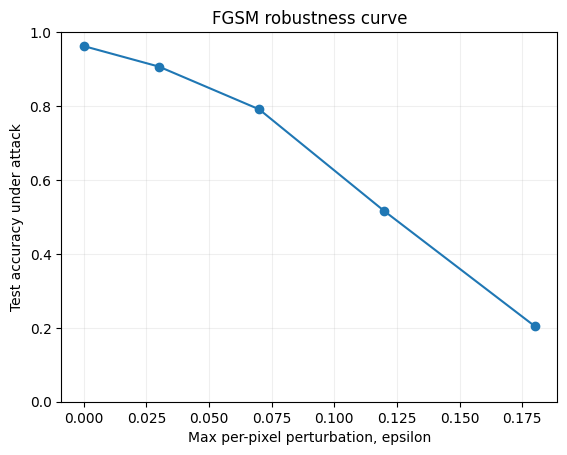

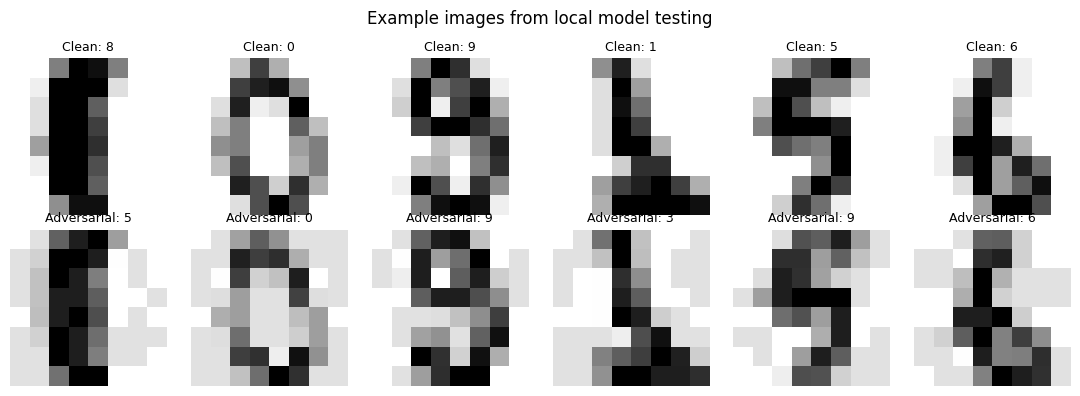

Max observed L-infinity change: 0.12
--- ran 4 code cells from AICS202_Lab02_FGSM_Evasion.ipynb ---
 epsilon  clean_acc  attacked_acc  drop_pp  max_linf_change  pred_changed  n_test  pixels_clipped_short_pct
    0.00     0.9622        0.9622      0.0             0.00             0     450                      0.00
    0.03     0.9622        0.9067      5.6             0.03            25     450                      0.00
    0.07     0.9622        0.7911     17.1             0.07            77     450                      2.84
    0.12     0.9622        0.5156     44.7             0.12           202     450                      2.84
    0.15     0.9622        0.3600     60.2             0.15           272     450                      5.55
    0.18     0.9622        0.2044     75.8             0.18           342     450                      5.55


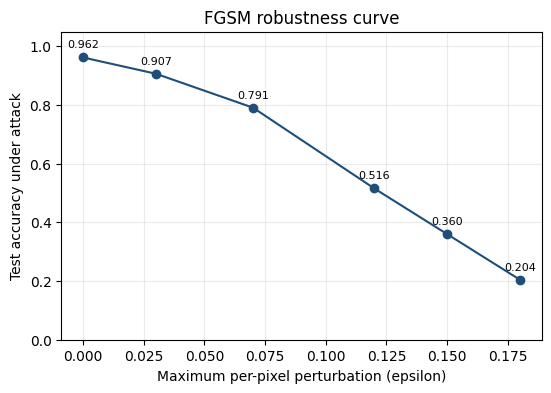

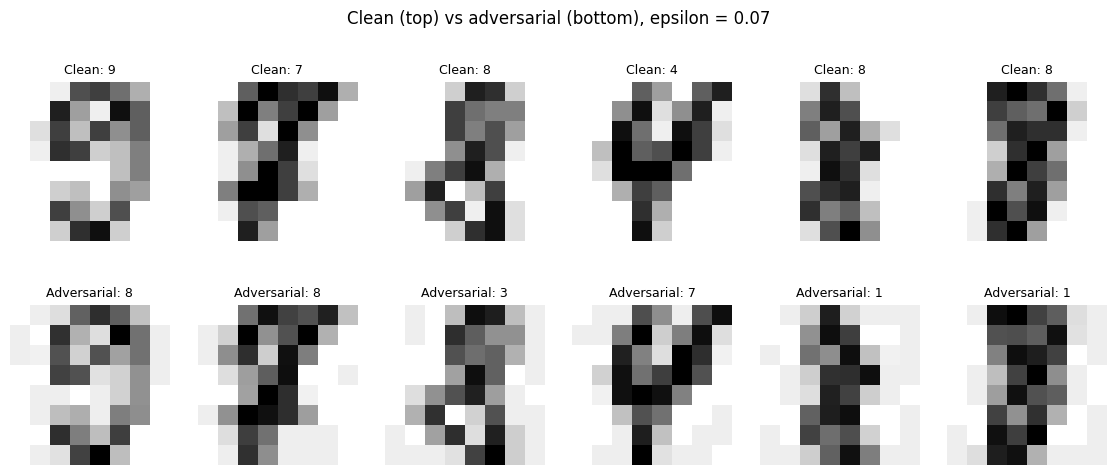

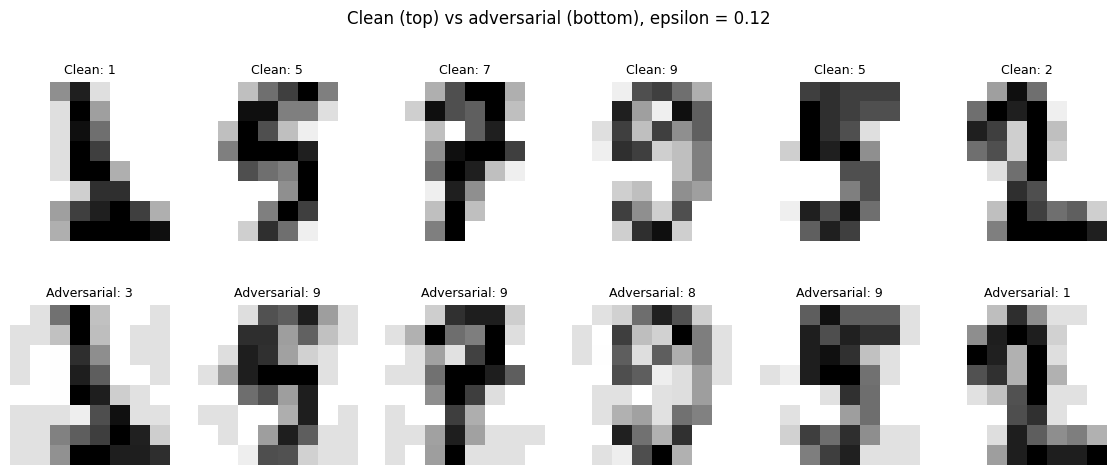

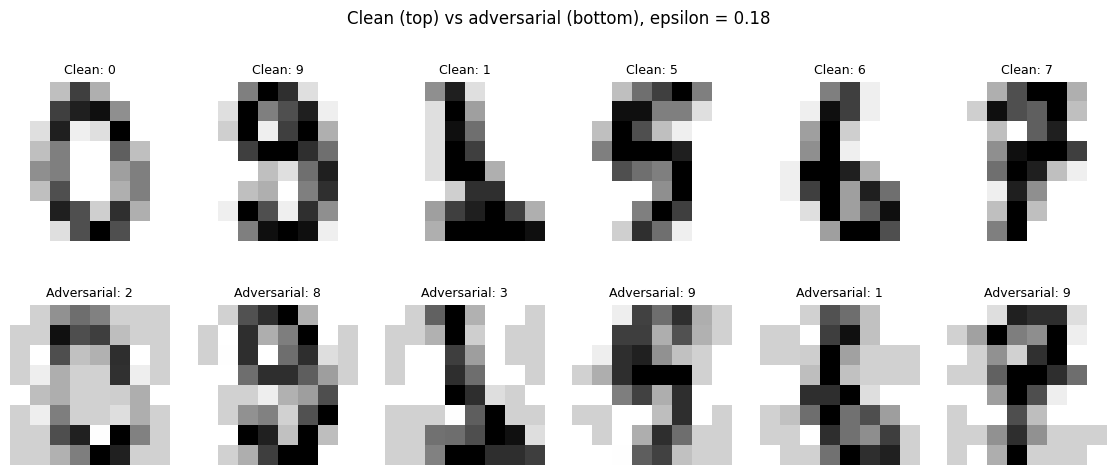

In [5]:
# ==== 3. LAB 02: FGSM EVASION (white-box, local model) ====
run_lab_notebook(LABS_DIR / LAB_FILES[2])
assert 'fgsm' in globals(), 'Lab 02 notebook did not define fgsm()'

clean_pred = model.predict(X_test); clean_acc = accuracy_score(y_test, clean_pred)
epsilons_used = sorted(set([0.00, 0.03, 0.07, 0.12, 0.18, round(ADDITIONAL_EPS, 2)]))     # notebook values + your own
rows = []
for eps in epsilons_used:
    adv = fgsm(model, X_test, y_test, epsilon=eps); p = model.predict(adv); d = np.abs(adv - X_test)
    rows.append({'epsilon': eps, 'clean_acc': round(clean_acc, 4), 'attacked_acc': round(accuracy_score(y_test, p), 4),
                 'drop_pp': round(100 * (clean_acc - accuracy_score(y_test, p)), 1), 'max_linf_change': round(float(d.max()), 4),
                 'pred_changed': int((p != clean_pred).sum()), 'n_test': len(y_test),
                 'pixels_clipped_short_pct': round(100 * float(np.mean((d > 1e-12) & (d < eps - 1e-12))), 2) if eps > 0 else 0.0})
res = pd.DataFrame(rows); res.to_csv(RESULTS / 'tables' / 'lab02_fgsm_results.csv', index=False); print(res.to_string(index=False))

plt.figure(figsize=(6.2, 4)); plt.plot(res.epsilon, res.attacked_acc, 'o-', color='#1F4E79')
for e, a in zip(res.epsilon, res.attacked_acc): plt.annotate(f'{a:.3f}', (e, a), textcoords='offset points', xytext=(0, 7), ha='center', fontsize=8)
plt.xlabel('Maximum per-pixel perturbation (epsilon)'); plt.ylabel('Test accuracy under attack'); plt.title('FGSM robustness curve')
plt.ylim(0, 1.05); plt.grid(alpha=.25); save_fig('lab02_robustness_curve'); plt.show()

ex_rows = []
for eps in [0.07, 0.12, 0.18]:
    adv = fgsm(model, X_test, y_test, epsilon=eps); p = model.predict(adv)
    flipped = np.where((clean_pred == y_test) & (p != y_test))[0][:6]
    fig, axes = plt.subplots(2, len(flipped), figsize=(1.9 * len(flipped), 4.8))
    for j, k in enumerate(flipped):
        axes[0, j].imshow(X_test[k].reshape(8, 8), cmap='gray_r', vmin=0, vmax=1); axes[0, j].set_title(f'Clean: {clean_pred[k]}', fontsize=9)
        axes[1, j].imshow(adv[k].reshape(8, 8), cmap='gray_r', vmin=0, vmax=1); axes[1, j].set_title(f'Adversarial: {p[k]}', fontsize=9)
        if eps == 0.12: ex_rows.append({'test_index': int(k), 'true_label': int(y_test[k]), 'clean_prediction': int(clean_pred[k]), 'adversarial_prediction': int(p[k])})
    for ax in axes.ravel(): ax.axis('off')
    plt.suptitle(f'Clean (top) vs adversarial (bottom), epsilon = {eps}'); plt.tight_layout(rect=[0, 0, 1, 0.93]); plt.subplots_adjust(hspace=0.4)
    save_fig(f'lab02_pairs_eps_{eps}'); plt.show()
examples = pd.DataFrame(ex_rows); examples.to_csv(RESULTS / 'tables' / 'lab02_example_changes_eps0.12.csv', index=False)
R['lab02'] = dict(res=res, examples=examples, clean_acc=clean_acc, eps_list=epsilons_used, extra_eps=round(ADDITIONAL_EPS, 2))


#Lab 03: Label poisoning and dataset integrity

Dataset: (1797, 64) | Train: 1347 | Test: 450
Clean test accuracy: 0.9622
Corruption 0%: 0 labels changed | Clean test accuracy 0.962
Corruption 5%: 67 labels changed | Clean test accuracy 0.960
Corruption 10%: 135 labels changed | Clean test accuracy 0.958
Corruption 20%: 269 labels changed | Clean test accuracy 0.933


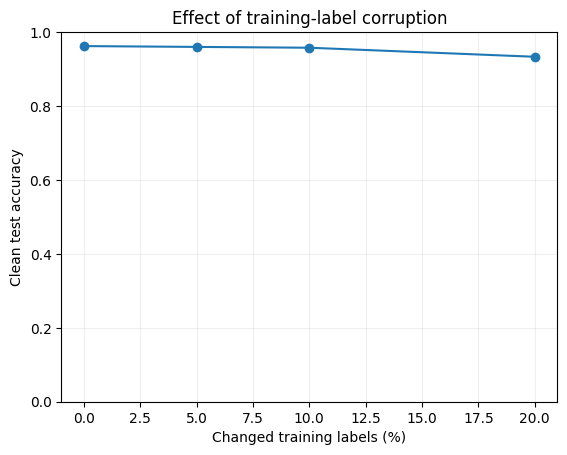

--- ran 2 code cells from AICS202_Lab03_Poisoning_Data_Integrity.ipynb ---


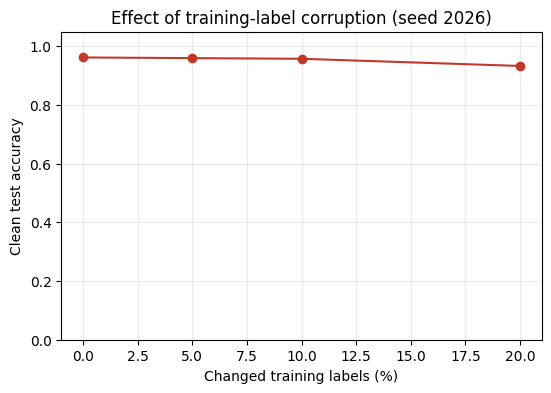

Check passed: re-created corrupted labels reproduce the notebook accuracies exactly.


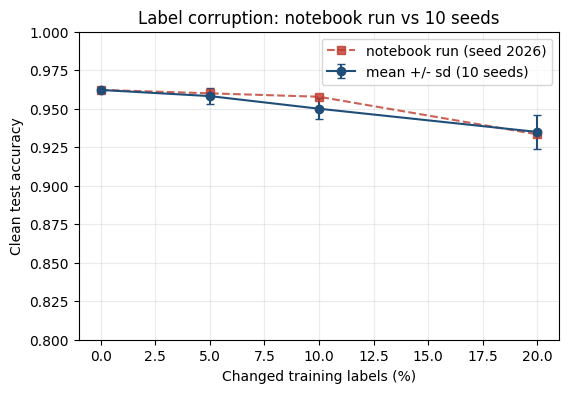

Training-label hash changed after 20% corruption: True | labels differing: 269
Held-out test images and labels unchanged (hash check): True
Label audit at 10% corruption: {'flagged': 185, 'n_corrupted': 135, 'precision': 0.7189189189189189, 'recall': 0.9851851851851852}
            mean     std     min     max
fraction                                
0.00      0.9622  0.0000  0.9622  0.9622
0.05      0.9582  0.0050  0.9467  0.9644
0.10      0.9500  0.0067  0.9400  0.9622
0.20      0.9349  0.0113  0.9178  0.9511


In [6]:
# ==== 4. LAB 03: LABEL POISONING AND DATASET INTEGRITY ====
run_lab_notebook(LABS_DIR / LAB_FILES[3])          # produces the notebook's own `records` (seed 2026)
assert 'records' in globals(), 'Lab 03 notebook did not produce `records`'
single = pd.DataFrame(records, columns=['fraction', 'n_labels_changed', 'clean_test_acc']); single.to_csv(RESULTS / 'tables' / 'lab03_single_run.csv', index=False)
plt.figure(figsize=(6.2, 4)); plt.plot([r[0] * 100 for r in records], [r[2] for r in records], 'o-', color='#C0392B')
plt.xlabel('Changed training labels (%)'); plt.ylabel('Clean test accuracy'); plt.title('Effect of training-label corruption (seed 2026)')
plt.ylim(0, 1.05); plt.grid(alpha=.25); save_fig('lab03_label_corruption'); plt.show()

# Re-create the notebook's exact corrupted label sets (same seed, same order) so we can hash and audit them
def sha(a): return hashlib.sha256(np.ascontiguousarray(a).tobytes()).hexdigest()
manifest = {'X_train': sha(X_train), 'y_train': sha(y_train), 'X_test': sha(X_test), 'y_test': sha(y_test)}
json.dump(manifest, open(RESULTS / 'evidence' / 'lab03_hash_manifest.json', 'w'), indent=2)
levels = [0.00, 0.05, 0.10, 0.20]; rng_chk = np.random.default_rng(2026); poisoned = {}
for f in levels:
    lab = y_train.copy(); n = round(len(lab) * f); sel = rng_chk.choice(len(lab), size=n, replace=False)
    lab[sel] = (lab[sel] + rng_chk.integers(1, 10, size=n)) % 10; poisoned[f] = (lab, sel)
for f, (lab, sel), rec in zip(levels, poisoned.values(), records):          # proves the re-creation matches the notebook run
    assert np.isclose(accuracy_score(y_test, build_model(X_train, lab).predict(X_test)), rec[2]), 'Re-created labels do not match the notebook run'
print('Check passed: re-created corrupted labels reproduce the notebook accuracies exactly.')

# Supplementary: 10 independent corruption seeds (explains non-monotonic behaviour)
def corrupt(labels, fraction, rng):
    out = labels.copy(); n = round(len(out) * fraction); s = rng.choice(len(out), size=n, replace=False)
    out[s] = (out[s] + rng.integers(1, 10, size=n)) % 10; return out
rows = [{'seed': s, 'fraction': f, 'acc': accuracy_score(y_test, build_model(X_train, corrupt(y_train, f, np.random.default_rng(s))).predict(X_test))} for s in range(10) for f in levels]
summ = pd.DataFrame(rows).groupby('fraction').acc.agg(['mean', 'std', 'min', 'max']).round(4); summ.to_csv(RESULTS / 'tables' / 'lab03_multiseed_summary.csv')
plt.figure(figsize=(6.2, 4)); plt.errorbar([f * 100 for f in summ.index], summ['mean'], yerr=summ['std'], fmt='o-', capsize=3, color='#1F4E79', label='mean +/- sd (10 seeds)')
plt.plot([r[0] * 100 for r in records], [r[2] for r in records], 's--', color='#C0392B', alpha=.8, label='notebook run (seed 2026)')
plt.xlabel('Changed training labels (%)'); plt.ylabel('Clean test accuracy'); plt.title('Label corruption: notebook run vs 10 seeds')
plt.ylim(0.8, 1.0); plt.grid(alpha=.25); plt.legend(); save_fig('lab03_multiseed'); plt.show()

# Integrity controls demonstrated in code
lab20, _ = poisoned[0.20]; lab10, sel10 = poisoned[0.10]
hash_changed = sha(lab20) != manifest['y_train']; test_unchanged = (sha(X_test) == manifest['X_test']) and (sha(y_test) == manifest['y_test'])
cvp = cross_val_predict(LogisticRegression(max_iter=600, random_state=SEED), X_train, lab10, cv=5)       # independent label audit
flag = cvp != lab10; truth = np.zeros(len(lab10), bool); truth[sel10] = True
audit = dict(flagged=int(flag.sum()), n_corrupted=int(truth.sum()), precision=float((flag & truth).sum() / max(flag.sum(), 1)), recall=float((flag & truth).sum() / truth.sum()))
print('Training-label hash changed after 20% corruption:', hash_changed, '| labels differing:', int((lab20 != y_train).sum()))
print('Held-out test images and labels unchanged (hash check):', test_unchanged); print('Label audit at 10% corruption:', audit); print(summ)
R['lab03'] = dict(single=single, summ=summ, manifest=manifest, hash_changed=bool(hash_changed), test_unchanged=bool(test_unchanged), n_changed20=int((lab20 != y_train).sum()), audit=audit)


#Lab 04: Defensive retraining and adaptive assessment

Dataset: (1797, 64) | Train: 1347 | Test: 450
Clean test accuracy: 0.9622
Baseline: clean=0.962 | FGSM=0.516 | PGD=0.489
Augmented training: clean=0.940 | FGSM=0.284 | PGD=0.260


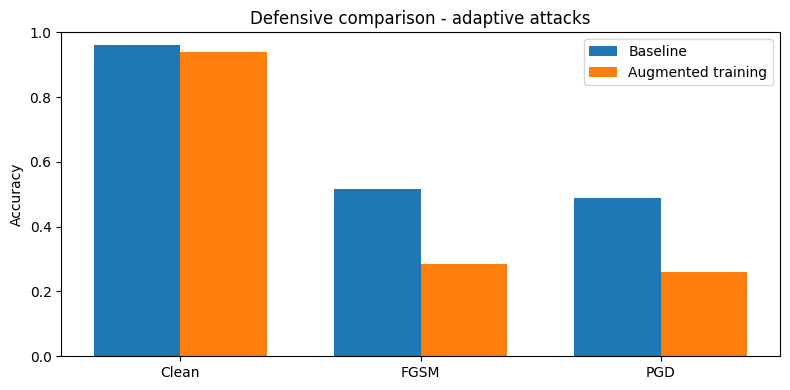

--- ran 4 code cells from AICS202_Lab04_Robustness_Defences.ipynb ---
                            variant  clean   fgsm    pgd  fgsm_transfer_from_baseline
                           Baseline 0.9622 0.5156 0.4889                       0.5156
Aug A: eps 0.10, 1 round (notebook) 0.9400 0.2844 0.2600                       0.8600
           Aug B: eps 0.03, 1 round 0.9622 0.4667 0.4378                       0.5800
           Aug C: eps 0.05, 1 round 0.9578 0.4333 0.4022                       0.7022
        Student: eps 0.05, 3 rounds 0.9667 0.4756 0.4667                       0.5733


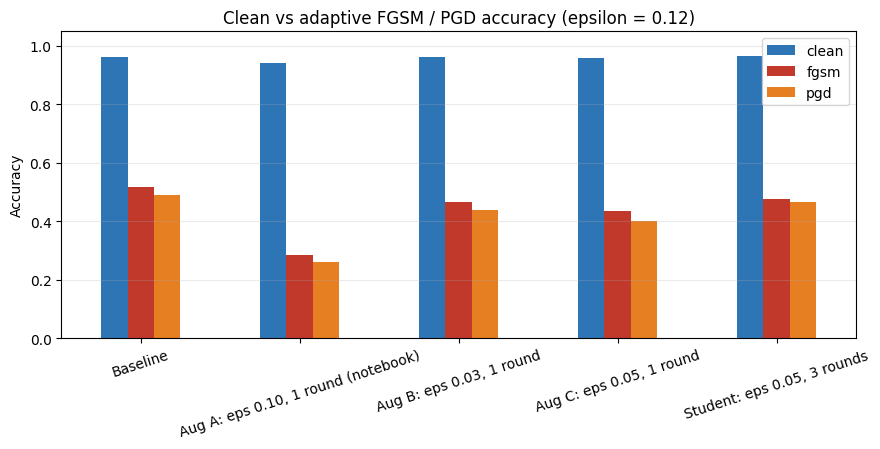

In [7]:
# ==== 5. LAB 04: DEFENSIVE RETRAINING AND ADAPTIVE ASSESSMENT ====
run_lab_notebook(LABS_DIR / LAB_FILES[4])          # defines pgd(), the notebook's defended model and evaluate()
assert 'pgd' in globals() and 'defended' in globals(), 'Lab 04 notebook did not define pgd()/defended'

EPS_EVAL = 0.12
X_fgsm_transfer = fgsm(model, X_test, y_test, epsilon=EPS_EVAL)        # crafted against the BASELINE only (non-adaptive replay)
def eval_row(m, name):
    clean = accuracy_score(y_test, m.predict(X_test))
    f = accuracy_score(y_test, m.predict(fgsm(m, X_test, y_test, EPS_EVAL)))             # adaptive: crafted against m itself
    p = accuracy_score(y_test, m.predict(pgd(m, X_test, y_test, EPS_EVAL, 0.03, 7)))     # adaptive PGD against m
    t = accuracy_score(y_test, m.predict(X_fgsm_transfer))
    return {'variant': name, 'clean': round(clean, 4), 'fgsm': round(f, 4), 'pgd': round(p, 4), 'fgsm_transfer_from_baseline': round(t, 4)}

def adv_train(eps, rounds=1, frac=1.0, seed=0):
    """Improvement study: adversarial augmentation. rounds=1, frac=1 matches the notebook's defence."""
    rng = np.random.default_rng(seed); m = build_model(X_train, y_train); Xa, ya = [X_train], [y_train]
    for _ in range(rounds):                         # each round regenerates samples against the CURRENT model
        idx = rng.choice(len(X_train), int(frac * len(X_train)), replace=False)
        Xa.append(fgsm(m, X_train[idx], y_train[idx], eps)); ya.append(y_train[idx])
        m = build_model(np.concatenate(Xa), np.concatenate(ya))
    return m

configs = [('Baseline', model), ('Aug A: eps 0.10, 1 round (notebook)', defended), ('Aug B: eps 0.03, 1 round', adv_train(0.03)),
           ('Aug C: eps 0.05, 1 round', adv_train(0.05)), ('Student: eps 0.05, 3 rounds', adv_train(0.05, rounds=3))]   # last row changes ONE factor vs Aug C
tab = pd.DataFrame([eval_row(m, n) for n, m in configs]); tab.to_csv(RESULTS / 'tables' / 'lab04_comparison.csv', index=False); print(tab.to_string(index=False))
ax = tab.set_index('variant')[['clean', 'fgsm', 'pgd']].plot.bar(figsize=(9, 4.6), rot=18, color=['#2E75B6', '#C0392B', '#E67E22'])
ax.set_ylim(0, 1.05); ax.set_ylabel('Accuracy'); ax.set_xlabel(''); ax.set_title('Clean vs adaptive FGSM / PGD accuracy (epsilon = 0.12)'); ax.grid(axis='y', alpha=.25)
plt.tight_layout(); save_fig('lab04_comparison'); plt.show()
R['lab04'] = dict(tab=tab, eps=EPS_EVAL)


#Threat model, risk register, integrity plan, recommendations

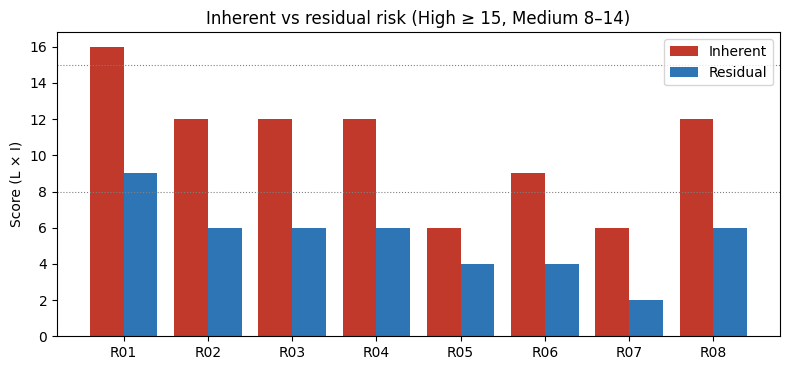

 ID  Inherent Rating  Residual ResRating
R01        16   High         9    Medium
R02        12 Medium         6       Low
R03        12 Medium         6       Low
R04        12 Medium         6       Low
R05         6    Low         4       Low
R06         9 Medium         4       Low
R07         6    Low         2       Low
R08        12 Medium         6       Low


In [8]:
# ==== 6. THREAT MODEL, RISK REGISTER, INTEGRITY PLAN, RECOMMENDATIONS ====
THREAT_MODEL = [
 ('Protected model and asset', 'Locally trained logistic-regression digit classifier. The asset is the integrity of its predictions and of the training data that produced them.'),
 ('Legitimate purpose', 'Classify 8 × 8 grayscale handwritten-digit images into the classes 0–9 for a learner-owned laboratory system.'),
 ('Attacker objective', 'Untargeted: cause any wrong prediction (evasion, Lab 2) or degrade the learned model (poisoning, Lab 3). No target class is defined.'),
 ('Attacker knowledge', 'White-box for evasion: model coefficients and loss gradients are known. This is a testing assumption, not evidence about a real attacker.'),
 ('Attacker control', 'Evasion: pixel values of inference inputs. Poisoning: labels in the training partition only. The held-out test set is never modified.'),
 ('Success criteria', 'Evasion: drop in held-out accuracy under an L-infinity budget. Poisoning: drop in clean held-out accuracy versus the 0% reference.'),
 ('Constraints', 'Features clipped to [0, 1]; epsilon bounds each pixel change; labels replaced only with a different class; local data and models only.'),
 ('Likely controls', 'Input range and shape validation, confidence monitoring, query logging and rate limiting, human review, dataset hashing, role-restricted writes, staged approval.'),
 ('Control owner', 'Model owner (change approval), data owner (dataset integrity), security reviewer (adversarial testing), supervisor (risk acceptance).'),
]
# id, risk, L, I, owner, control, residual L, residual I
RISKS = [
 ('R01', 'Evasion by bounded input perturbation (FGSM/PGD)', 4, 4, 'Model owner', 'Input validation, confidence/margin monitoring, human review of low-margin outputs, adaptive re-testing', 3, 3),
 ('R02', 'Training-label poisoning or accidental label noise', 3, 4, 'Data owner', 'Label audit, versioned labels, staged approval, accuracy-shift alerts', 2, 3),
 ('R03', 'Weak dataset provenance or supply-chain change', 3, 4, 'Data owner', 'Provenance register, SHA-256 manifest, restricted write access', 2, 3),
 ('R04', 'Defence overconfidence (non-adaptive or single-benchmark testing)', 4, 3, 'Security reviewer', 'Model-specific FGSM/PGD tests, multiple seeds and budgets, negative results recorded', 2, 3),
 ('R05', 'Model extraction or privacy leakage (conceptual in this course)', 2, 3, 'Model owner', 'Rate limiting, query logging, access control on prediction interface', 2, 2),
 ('R06', 'Undetected drift or degradation after deployment', 3, 3, 'Model owner', 'Monitoring dashboard, scheduled re-evaluation, rollback criteria', 2, 2),
 ('R07', 'Irreproducible or hidden-state experimental evidence', 3, 2, 'Learner / reviewer', 'Fixed seeds, version log, restart-and-run-all, evidence index', 1, 2),
 ('R08', 'Model change released without independent sign-off', 3, 4, 'Governance board', 'Staged approval, named approver, documented decision memo', 2, 3),
]
def rating(s): return 'High' if s >= 15 else ('Medium' if s >= 8 else 'Low')
risk_df = pd.DataFrame([dict(ID=r[0], Risk=r[1], L=r[2], I=r[3], Inherent=r[2]*r[3], Rating=rating(r[2]*r[3]), Owner=r[4], Control=r[5],
                             RL=r[6], RI=r[7], Residual=r[6]*r[7], ResRating=rating(r[6]*r[7])) for r in RISKS])
risk_df.to_csv(RESULTS / 'tables' / 'risk_register.csv', index=False)

fig, ax = plt.subplots(figsize=(8, 3.8)); xs = np.arange(len(risk_df))
ax.bar(xs - .2, risk_df.Inherent, .4, label='Inherent', color='#C0392B'); ax.bar(xs + .2, risk_df.Residual, .4, label='Residual', color='#2E75B6')
ax.axhline(15, ls=':', c='grey', lw=.8); ax.axhline(8, ls=':', c='grey', lw=.8)
ax.set_xticks(xs); ax.set_xticklabels(risk_df.ID); ax.set_ylabel('Score (L × I)'); ax.set_title('Inherent vs residual risk (High ≥ 15, Medium 8–14)'); ax.legend()
plt.tight_layout(); save_fig('risk_inherent_vs_residual'); plt.show()

INTEGRITY_CONTROLS = [
 ('Dataset provenance register', 'Procedural', 'Records source, licence and permitted use so unexpected data can be challenged.', 'Source: scikit-learn load_digits; educational use only.', 'Partly'),
 ('Cryptographic hash manifest', 'Technical', 'Detects any change to features or labels between approval and training.', 'SHA-256 of X/y train/test stored in lab03_hash_manifest.json.', 'Yes'),
 ('Restricted write access', 'Technical', 'Limits who can modify training data or labels.', 'Design control; role-based permissions would be enforced on the data store.', 'Yes'),
 ('Versioned labels with reviewer identity', 'Procedural', 'Gives an audit trail and a rollback point after a bad change.', 'Design control; each label change needs a recorded reviewer.', 'Partly'),
 ('Independent label audit', 'Technical', 'Flags labels that disagree with an independent model prediction.', 'Cross-validated disagreement audit run on the 10% corrupted set (see Section 5.4).', 'Yes'),
 ('Staged dataset approval and sign-off', 'Procedural', 'Separates data preparation from training and deployment.', 'Signed-off integrity checklist (Appendix B).', 'No'),
 ('Anomaly review of accuracy shifts', 'Technical', 'Unexplained accuracy change after a data refresh triggers investigation.', 'Escalation path in Section 5.7; thresholds set by the model owner.', 'Yes'),
]
CHRONOLOGY = [
 ('1. Collection / source', 'Upstream source or collector supplies mislabelled or manipulated samples.', 'Provenance register; source checks'),
 ('2. Labelling and approval', 'Label-approval step bypassed or labels edited without review.', 'Versioned labels; reviewer identity; approval log'),
 ('3. Storage', 'Unauthorised write to the training data store.', 'Role-restricted writes; hash manifest comparison'),
 ('4. Training', 'Altered partition consumed by a training job.', 'Hash verification before every training run'),
 ('5. Evaluation / deployment', 'Accuracy falls or behaves unexpectedly after a data refresh.', 'Label audit; accuracy-shift alert; escalation path'),
]
ESCALATION = ['Detect: automated accuracy-shift alert or hash mismatch raises an incident ticket.',
              'Contain: freeze the dataset version and stop training jobs that use it; keep the last approved model in service.',
              'Investigate: compare dataset versions and hashes, run the independent label audit, separate label noise, upstream change, drift and deliberate corruption.',
              'Recover: roll back to the last approved dataset version, retrain, and re-run clean, FGSM and PGD tests.',
              'Approve: designated reviewer signs off the retrained model before release; lessons are recorded in the risk register.']
RECOMMENDATIONS = [
 ('Critical', 'Adopt model-specific (adaptive) FGSM/PGD testing as a release gate for any model or defence change', 'Security reviewer', 'Before any release', 'Gate evidenced in every change record'),
 ('Critical', 'Create a dataset hash manifest and verify it before each training run', 'Data owner', 'Before next training', 'Mismatch blocks training; log retained'),
 ('High', 'Implement input validation, confidence monitoring and human review of low-margin predictions', 'Model owner', '0–3 months', 'Alerts tested in a drill'),
 ('High', 'Introduce versioned labels, restricted write access and staged dataset approval', 'Data owner / Governance board', '0–3 months', 'Every label change has a named reviewer'),
 ('Medium', 'Repeat evaluations over multiple seeds and perturbation budgets; record negative results', 'Security reviewer', '3–6 months', 'Mean and spread reported for each metric'),
 ('Medium', 'Extend testing beyond this lab: other model families, larger images, black-box and targeted threat models', 'Security reviewer', '6–12 months', 'Extended test report to governance board'),
]
print(risk_df[['ID', 'Inherent', 'Rating', 'Residual', 'ResRating']].to_string(index=False))


#Word-report toolkit

In [9]:
# ==== 7. WORD-REPORT TOOLKIT (styles, tables, figures, cover page) ====
try:
    import docx
except ImportError:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'python-docx'], check=True); import docx
from docx import Document
from docx.shared import Pt, Cm, RGBColor, Inches
from docx.enum.text import WD_ALIGN_PARAGRAPH, WD_BREAK
from docx.oxml.ns import qn
from docx.oxml import OxmlElement

NAVY, BLUE, LIGHT, GREY = '1F4E79', '2E75B6', 'EEF3FA', '595959'
PPR = ['pStyle','keepNext','keepLines','pageBreakBefore','framePr','widowControl','numPr','suppressLineNumbers','pBdr','shd','tabs','suppressAutoHyphens',
       'kinsoku','wordWrap','overflowPunct','topLinePunct','autoSpaceDE','autoSpaceDN','bidi','adjustRightInd','snapToGrid','spacing','ind','contextualSpacing',
       'mirrorIndents','suppressOverlap','jc','textDirection','textAlignment','textboxTightWrap','outlineLvl','divId','cnfStyle','rPr','sectPr','pPrChange']
TCPR = ['cnfStyle','tcW','gridSpan','hMerge','vMerge','tcBorders','shd','noWrap','tcMar','textDirection','tcFitText','vAlign','hideMark']
def put(parent, el, order):
    name = el.tag.split('}')[1]; idx = order.index(name)
    for ch in parent:
        cn = ch.tag.split('}')[1]
        if cn in order and order.index(cn) > idx: ch.addprevious(el); return
    parent.append(el)
def shade_cell(cell, fill):
    shd = OxmlElement('w:shd'); shd.set(qn('w:val'), 'clear'); shd.set(qn('w:color'), 'auto'); shd.set(qn('w:fill'), fill); put(cell._tc.get_or_add_tcPr(), shd, TCPR)
def cell_borders(cell, **edges):
    b = OxmlElement('w:tcBorders')
    for e in ('top', 'left', 'bottom', 'right'):
        el = OxmlElement(f'w:{e}'); v = edges.get(e)
        if v: el.set(qn('w:val'), 'single'); el.set(qn('w:sz'), str(v[0])); el.set(qn('w:space'), '0'); el.set(qn('w:color'), v[1])
        else: el.set(qn('w:val'), 'nil')
        b.append(el)
    put(cell._tc.get_or_add_tcPr(), b, TCPR)
def para_shade(p, fill):
    shd = OxmlElement('w:shd'); shd.set(qn('w:val'), 'clear'); shd.set(qn('w:color'), 'auto'); shd.set(qn('w:fill'), fill); put(p._p.get_or_add_pPr(), shd, PPR)
def para_border(pPr_owner, side='bottom', sz=12, color=BLUE, space=3):
    pb = OxmlElement('w:pBdr'); el = OxmlElement(f'w:{side}')
    el.set(qn('w:val'), 'single'); el.set(qn('w:sz'), str(sz)); el.set(qn('w:space'), str(space)); el.set(qn('w:color'), color); pb.append(el); put(pPr_owner, pb, PPR)
def add_field(par, code, size=9, color=GREY):
    for t, txt in (('begin', None), ('instr', f' {code} '), ('separate', None), ('text', '1'), ('end', None)):
        r = par.add_run(); r.font.size = Pt(size); r.font.color.rgb = RGBColor.from_string(color)
        if t == 'instr': e = OxmlElement('w:instrText'); e.set(qn('xml:space'), 'preserve'); e.text = txt; r._r.append(e)
        elif t == 'text': r.text = txt
        else: e = OxmlElement('w:fldChar'); e.set(qn('w:fldCharType'), t); r._r.append(e)

def runs(p, text, size=None, color=None, italic=False, bold=False):
    for i, t in enumerate(str(text).split('**')):
        if not t: continue
        r = p.add_run(t); r.bold = bold or (i % 2 == 1); r.italic = italic
        if size: r.font.size = Pt(size)
        if color: r.font.color.rgb = RGBColor.from_string(color)
    return p

class Report:
    def __init__(self):
        d = self.doc = Document(); s = d.sections[0]
        s.page_width, s.page_height = Cm(21), Cm(29.7)
        s.left_margin = s.right_margin = Cm(2.0); s.top_margin, s.bottom_margin = Cm(2.4), Cm(2.0); s.header_distance = Cm(1.0)
        s.different_first_page_header_footer = True
        self.text_w = 17.0
        st = d.styles
        n = st['Normal']; n.font.name = 'Calibri'; n.font.size = Pt(10.5)
        n.element.rPr.rFonts.set(qn('w:eastAsia'), 'Calibri')
        n.paragraph_format.space_after = Pt(6); n.paragraph_format.line_spacing = 1.12
        for name, size, color, before, after in (('Heading 1', 18, NAVY, 16, 6), ('Heading 2', 13, BLUE, 10, 4), ('Heading 3', 11, NAVY, 8, 3)):
            h = st[name]; h.font.name = 'Calibri'; h.font.size = Pt(size); h.font.bold = True; h.font.italic = False; h.font.color.rgb = RGBColor.from_string(color)
            rf = h.element.rPr.rFonts
            for a in ('asciiTheme', 'hAnsiTheme', 'eastAsiaTheme', 'cstheme'): rf.attrib.pop(qn('w:' + a), None)
            rf.set(qn('w:ascii'), 'Calibri'); rf.set(qn('w:hAnsi'), 'Calibri'); rf.set(qn('w:eastAsia'), 'Calibri')
            h.paragraph_format.space_before = Pt(before); h.paragraph_format.space_after = Pt(after); h.paragraph_format.keep_with_next = True
        para_border(st['Heading 1'].element.get_or_add_pPr(), 'bottom', 12, BLUE, 3)
        lb = st['List Bullet']; lb.font.name = 'Calibri'; lb.font.size = Pt(10.5); lb.paragraph_format.space_after = Pt(3)
        hp = s.header.paragraphs[0]; hp.alignment = WD_ALIGN_PARAGRAPH.RIGHT
        runs(hp, 'Adversarial Machine Learning  |  AICS-202 Integrated Practical Assessment', 9, GREY); para_border(hp._p.get_or_add_pPr(), 'bottom', 4, 'BFBFBF', 4)
        fp = s.footer.paragraphs[0]; fp.alignment = WD_ALIGN_PARAGRAPH.CENTER
        runs(fp, 'Page ', 9, GREY); add_field(fp, 'PAGE'); runs(fp, ' of ', 9, GREY); add_field(fp, 'NUMPAGES')
        self.tn = 0; self.fn = 0; self.words = 0; self.body_done = False

    # ---------- text ----------
    def h1(self, t): return self.doc.add_heading(t, 1)
    def h2(self, t): return self.doc.add_heading(t, 2)
    def h3(self, t): return self.doc.add_heading(t, 3)
    def p(self, text, align='justify', italic=False, size=None, color=None, after=None, keep=False):
        par = self.doc.add_paragraph(); runs(par, text, size, color, italic)
        par.alignment = {'justify': WD_ALIGN_PARAGRAPH.JUSTIFY, 'left': WD_ALIGN_PARAGRAPH.LEFT, 'center': WD_ALIGN_PARAGRAPH.CENTER}[align]
        if after is not None: par.paragraph_format.space_after = Pt(after)
        par.paragraph_format.keep_with_next = keep
        if not self.body_done: self.words += len(str(text).replace('**', '').split())
        return par
    def bullets(self, items):
        for it in items:
            par = self.doc.add_paragraph(style='List Bullet'); runs(par, it); par.alignment = WD_ALIGN_PARAGRAPH.LEFT
            if not self.body_done: self.words += len(str(it).replace('**', '').split())
    def numbered(self, items):
        for i, it in enumerate(items, 1):
            par = self.doc.add_paragraph(); par.paragraph_format.left_indent = Cm(0.9); par.paragraph_format.first_line_indent = Cm(-0.6); par.paragraph_format.space_after = Pt(3)
            runs(par, f'{i}.  {it}')
            if not self.body_done: self.words += len(str(it).split())
    def page_break(self): self.doc.add_paragraph().add_run().add_break(WD_BREAK.PAGE)
    def caption(self, text, keep=False):
        par = self.doc.add_paragraph(); runs(par, text, 9, GREY, italic=True); par.alignment = WD_ALIGN_PARAGRAPH.CENTER
        par.paragraph_format.space_after = Pt(4 if keep else 10); par.paragraph_format.keep_with_next = keep; return par

    # ---------- tables ----------
    def table(self, headers, rows, widths, caption=None, size=9, fills=None, bold_first_col=False, align_center_cols=()):
        if caption: self.tn += 1; self.caption(f'Table {caption[0]}: {caption[1]}', keep=True)
        t = self.doc.add_table(rows=1, cols=len(headers)); t.autofit = False
        tot = sum(widths); widths = [w * self.text_w / tot for w in widths]
        def fill_cell(c, text, w, hdr=False, bg=None, bold=False, center=False):
            c.width = Cm(w); c.text = ''
            par = c.paragraphs[0]; par.paragraph_format.space_after = Pt(2); par.paragraph_format.space_before = Pt(2); par.paragraph_format.line_spacing = 1.0
            par.alignment = WD_ALIGN_PARAGRAPH.CENTER if (center or hdr) else WD_ALIGN_PARAGRAPH.LEFT
            runs(par, text, size, 'FFFFFF' if hdr else None, bold=hdr or bold)
            cell_borders(c, top=(4, 'BFBFBF'), left=(4, 'BFBFBF'), bottom=(4, 'BFBFBF'), right=(4, 'BFBFBF'))
            if hdr: shade_cell(c, NAVY)
            elif bg: shade_cell(c, bg)
        for i, h in enumerate(headers): fill_cell(t.rows[0].cells[i], h, widths[i], hdr=True)
        tr = t.rows[0]._tr.get_or_add_trPr(); e = OxmlElement('w:tblHeader'); e.set(qn('w:val'), 'true'); tr.append(e)
        for ri, row in enumerate(rows):
            cells = t.add_row().cells
            cs = OxmlElement('w:cantSplit'); t.rows[-1]._tr.get_or_add_trPr().append(cs)
            for ci, v in enumerate(row):
                bg = (fills or {}).get((ri, ci)) or (LIGHT if ri % 2 == 1 else None)
                fill_cell(cells[ci], v, widths[ci], bg=bg, bold=(bold_first_col and ci == 0), center=(ci in align_center_cols))
        for i, w in enumerate(widths): t.columns[i].width = Cm(w)
        mar = OxmlElement('w:tblCellMar')
        for side, w in (('top', 30), ('left', 80), ('bottom', 30), ('right', 80)):
            el = OxmlElement(f'w:{side}'); el.set(qn('w:w'), str(w)); el.set(qn('w:type'), 'dxa'); mar.append(el)
        t._tbl.tblPr.find(qn('w:tblLook')).addprevious(mar)
        self.doc.add_paragraph().paragraph_format.space_after = Pt(4)
        return t
    def df_table(self, df, caption, widths=None, size=9, fmt=None, **kw):
        fmt = fmt or {}
        rows = [[(fmt[c](v) if c in fmt else str(v)) for c, v in zip(df.columns, r)] for r in df.itertuples(index=False)]
        return self.table(list(df.columns), rows, widths or [1] * len(df.columns), caption, size, align_center_cols=tuple(range(1, len(df.columns))), **kw)
    def callout(self, title, text, fill='FFF8E1', bar='D4A017'):
        t = self.doc.add_table(rows=1, cols=1); t.autofit = False; c = t.rows[0].cells[0]; c.width = Cm(self.text_w); c.text = ''
        cell_borders(c, left=(36, bar)); shade_cell(c, fill)
        par = c.paragraphs[0]; par.paragraph_format.space_before = Pt(4); par.paragraph_format.space_after = Pt(4); par.alignment = WD_ALIGN_PARAGRAPH.JUSTIFY
        t.columns[0].width = Cm(self.text_w); runs(par, f'**{title}** ' + text, 9.5)
        self.doc.add_paragraph().paragraph_format.space_after = Pt(2)
    def figure(self, path, caption, width=6.2):
        par = self.doc.add_paragraph(); par.alignment = WD_ALIGN_PARAGRAPH.CENTER; par.paragraph_format.keep_with_next = True; par.paragraph_format.space_after = Pt(2)
        par.add_run().add_picture(str(path), width=Inches(width)); self.fn += 1
        self.caption(f'Figure {caption[0]}: {caption[1]}')

    def kv_table(self, rows, widths=(3.0, 14.0)):
        t = self.doc.add_table(rows=0, cols=2); t.autofit = False
        for k, v in rows:
            cells = t.add_row().cells
            for c, txt, w, lab in ((cells[0], k, widths[0], True), (cells[1], v, widths[1], False)):
                c.width = Cm(w); c.text = ''; par = c.paragraphs[0]; par.paragraph_format.space_before = Pt(3); par.paragraph_format.space_after = Pt(3)
                runs(par, txt, 10, bold=lab); cell_borders(c, bottom=(4, 'BFBFBF'), top=(4, 'BFBFBF'), left=(4, 'BFBFBF'), right=(4, 'BFBFBF'))
                if lab: shade_cell(c, LIGHT)
        for i, w in enumerate(widths): t.columns[i].width = Cm(w)
        self.doc.add_paragraph().paragraph_format.space_after = Pt(4)

    # ---------- cover ----------
    def cover(self, meta):
        d = self.doc
        top = d.add_paragraph(); runs(top, 'Local dataset only  |  Controlled laboratory  |  For academic assessment use only', 8.5, GREY, italic=True); top.alignment = WD_ALIGN_PARAGRAPH.CENTER
        b = d.add_paragraph(); b.paragraph_format.space_before = Pt(18); b.paragraph_format.space_after = Pt(0); b.alignment = WD_ALIGN_PARAGRAPH.CENTER; para_shade(b, NAVY)
        runs(b, 'INTERNATIONAL CYBERSECURITY & DIGITAL FORENSICS ACADEMY', 13, 'FFFFFF', bold=True)
        b2 = d.add_paragraph(); b2.alignment = WD_ALIGN_PARAGRAPH.CENTER; b2.paragraph_format.space_after = Pt(60); para_shade(b2, NAVY)
        runs(b2, 'ICDFA  ·  School of AI-Driven Cybersecurity and Digital Forensics', 10, 'DCE6F2')
        a = d.add_paragraph(); a.alignment = WD_ALIGN_PARAGRAPH.CENTER; runs(a, 'A S S E S S M E N T   R E P O R T', 12, BLUE, bold=True)
        t = d.add_paragraph(); t.alignment = WD_ALIGN_PARAGRAPH.CENTER; t.paragraph_format.space_before = Pt(10); runs(t, 'Adversarial Machine Learning', 30, NAVY, bold=True)
        t2 = d.add_paragraph(); t2.alignment = WD_ALIGN_PARAGRAPH.CENTER; runs(t2, 'AICS-202 Integrated Practical Assessment', 18, NAVY)
        sub = d.add_paragraph(); sub.alignment = WD_ALIGN_PARAGRAPH.CENTER; sub.paragraph_format.space_before = Pt(12); sub.paragraph_format.space_after = Pt(36)
        runs(sub, 'Baseline threat modelling, FGSM/PGD evasion testing, training-label integrity and adaptive defence evaluation on a locally owned classifier', 11.5, GREY, italic=True)
        tb = d.add_table(rows=0, cols=2); tb.autofit = False
        for k, v in meta:
            cells = tb.add_row().cells
            for c, txt, w, lab in ((cells[0], k, 4.6, True), (cells[1], v, 12.4, False)):
                c.width = Cm(w); c.text = ''; par = c.paragraphs[0]; par.paragraph_format.space_before = Pt(3); par.paragraph_format.space_after = Pt(3)
                runs(par, txt, 10, bold=lab); cell_borders(c, bottom=(4, 'BFBFBF'), top=(4, 'BFBFBF'))
                if lab: shade_cell(c, LIGHT)
        tb.columns[0].width = Cm(4.6); tb.columns[1].width = Cm(12.4)
        f = d.add_paragraph(); f.paragraph_format.space_before = Pt(40); f.alignment = WD_ALIGN_PARAGRAPH.CENTER
        runs(f, 'Defensive AI  ·  Local Data Only  ·  For Academic and Research Use Only', 9, GREY, italic=True)
        self.page_break()


#Build the professional Word report

In [10]:
# ==== 8. BUILD THE PROFESSIONAL WORD REPORT ====
L1, L2, L3, L4 = R['lab01'], R['lab02'], R['lab03'], R['lab04']
f3 = lambda v: f'{v:.3f}'; pc = lambda v: f'{100 * v:.1f}%'; sg = lambda v: f'{v:+.1f}'
res, ex, tab, single, summ = L2['res'], L2['examples'], L4['tab'], L3['single'], L3['summ']
rowe = lambda e: res[np.isclose(res.epsilon, e)].iloc[0]
e12, emax = rowe(0.12), res.iloc[-1]
base, augA = tab.iloc[0], tab.iloc[1]
cands = tab.iloc[1:].copy(); cands['avg_adv'] = (cands.fgsm + cands.pgd) / 2; best = cands.sort_values('avg_adv', ascending=False).iloc[0]
improved = cands[(cands.fgsm >= base.fgsm + 0.02) & (cands.pgd >= base.pgd + 0.02) & (cands.clean >= base.clean - 0.03)]
if len(improved): DECISION, DEC_TXT = 'IMPROVE', f'at least one tested variant ({", ".join(improved.variant)}) raised both adaptive FGSM and PGD accuracy by two or more percentage points without a large clean-accuracy cost, but one dataset, one model family and one seed are not enough to deploy it'
else: DECISION, DEC_TXT = 'REJECT (as a security control)', 'none of the tested augmentation variants raised both adaptive FGSM and PGD accuracy by two or more percentage points while keeping clean accuracy within three points of the baseline'
aA_f, aA_p, aA_c = (augA.fgsm - base.fgsm) * 100, (augA.pgd - base.pgd) * 100, (augA.clean - base.clean) * 100
ms0, ms20 = summ.loc[0.00, 'mean'], summ.loc[0.20, 'mean']; s20 = single.iloc[-1]
nonmono_single = any(single.clean_test_acc.iloc[i + 1] > single.clean_test_acc.iloc[i] for i in range(len(single) - 1))
nonmono_mean = any(summ['mean'].iloc[i + 1] > summ['mean'].iloc[i] for i in range(len(summ) - 1))
today = datetime.datetime.now().strftime('%d %B %Y')
AI_DECLARATION = ('I used AI assistance in preparing this assessment. Claude (developed by Anthropic) helped me plan the practical workflow, write the Python code '
  'that runs the four laboratories and generates this report, and draft the report structure and wording. I ran the notebook in Google Colab, checked that every '
  'figure and table in this report is produced by the executed notebook (no illustrative values from the manual were used), reviewed and edited the text, and cross-checked '
  'the references against the sources listed in Section 9. I can explain and demonstrate every calculation on request.')

D = Report()
D.cover([('Name', STUDENT_NAME), ('Registration number', REG_NO), ('Cohort', COHORT), ('Course', 'AICS-202 Adversarial Machine Learning'),
         ('Assessment', 'Integrated practical assessment (Labs 01–04), 100 marks'), ('Compute and tools', f"{ENV['platform']} (Python {ENV['python']}, scikit-learn {ENV['scikit-learn']}, numpy {ENV['numpy']}, matplotlib {ENV['matplotlib']}); fixed random seed 42"),
         ('Data used', f"scikit-learn load_digits: {L1['n_total']:,} images of handwritten digits (8 × 8 pixels), offline and unmodified"),
         ('GitHub repository', GITHUB_URL), ('AI assistance', 'Declared in Appendix G'), ('Date', today)])

D.h1('Contents')
for line in ['1. Executive Summary', '2. Scope, Environment and Method', '3. Baseline Model and Threat Model (Lab 01)', '4. Evasion Testing with FGSM (Lab 02)',
             '5. Training-Label Poisoning and Dataset Integrity (Lab 03)', '6. Defensive Retraining and Adaptive Assessment (Lab 04)',
             '7. Risk Register and Prioritised Recommendations', '8. Limitations, Reproducibility and Conclusion', '9. References',
             'Appendix A: Threat Model Worksheet', 'Appendix B: Dataset Integrity Register and Incident Chronology', 'Appendix C: Defensive Decision Memo',
             'Appendix D: Supplementary Results', 'Appendix E: Evidence Log and Index', 'Appendix F: Assumptions and Limitations', 'Appendix G: AI-Assistance Declaration',
             'Appendix H: Repository and Reproducibility']:
    D.p(line, align='left', after=3)
D.page_break()

# ---------------------------------------------------------------- 1
D.h1('1. Executive Summary')
D.p(f"This report presents the integrated practical assessment for AICS-202 Adversarial Machine Learning. Four controlled laboratories were run on a classifier owned by the author, "
    f"trained on the offline scikit-learn digits dataset ({L1['n_total']:,} images of 8 × 8 pixels). They examine evasion at inference time, poisoning of training labels and a simple "
    f"defensive retraining approach, and the measurements are turned into a threat model, a dataset-integrity plan, a risk register and a deployment decision.")
D.p(f"The baseline logistic-regression model reached a clean accuracy of **{pc(base.clean)}** on {L1['n_test']} held-out images. A white-box, untargeted FGSM attack with an L-infinity budget of 0.12 "
    f"reduced accuracy to **{pc(e12.attacked_acc)}**, a loss of {e12.drop_pp:.1f} percentage points, and a budget of {emax.epsilon:.2f} reduced it to {pc(emax.attacked_acc)}. "
    f"Replacing 20% of the training labels lowered clean test accuracy from {pc(single.clean_test_acc.iloc[0])} to {pc(s20.clean_test_acc)} in the primary run "
    f"(mean {pc(ms20)} over ten corruption seeds), which shows that random label noise degraded the model modestly in this experiment. A SHA-256 manifest detected the label change and confirmed "
    f"that the held-out test partition was untouched.")
D.p(f"The notebook's adversarial-augmentation defence changed adaptive FGSM accuracy by {sg(aA_f)} percentage points and adaptive PGD accuracy by {sg(aA_p)} points, with a clean-accuracy change of {sg(aA_c)} points. "
    f"Across all variants tested, the decision is **{DECISION}**: {DEC_TXT}. These results are specific to this small dataset, this model family and the stated attacker assumptions. "
    f"They are not a certification of model security, and every figure in this report was produced by the executed notebook rather than taken from the course manual.")
D.table(['Headline result', 'Value'], [
    ['Clean test accuracy (baseline)', f"{pc(base.clean)} ({L1['n_test']} test images)"],
    ['FGSM accuracy at epsilon 0.12 / largest epsilon tested', f"{pc(e12.attacked_acc)} / {pc(emax.attacked_acc)} (epsilon {emax.epsilon:.2f})"],
    ['Accuracy drop at epsilon 0.12', f"{e12.drop_pp:.1f} percentage points"],
    ['Accuracy with 20% labels corrupted (primary run / 10-seed mean)', f"{pc(s20.clean_test_acc)} / {pc(ms20)}"],
    ['Label audit at 10% corruption (precision / recall)', f"{L3['audit']['precision']:.2f} / {L3['audit']['recall']:.2f}"],
    ['Augmentation A (notebook): FGSM / PGD change vs baseline', f"{sg(aA_f)} / {sg(aA_p)} percentage points"],
    ['Best variant by mean adaptive accuracy', f"{best.variant} (FGSM {pc(best.fgsm)}, PGD {pc(best.pgd)})"],
    ['Decision', DECISION]], [3.2, 2.2], caption=('1.1', 'Summary of headline results'), size=9.5, bold_first_col=True)

# ---------------------------------------------------------------- 2
D.h1('2. Scope, Environment and Method')
D.p("**Authorised scope.** All experiments use only the bundled scikit-learn digits dataset and models trained by the author in the notebook. No production service, public API, third-party model or personal data was accessed. "
    "The work follows the course boundary that any test of a non-laboratory asset requires prior written authorisation.")
D.p("**Method.** The four laboratories were executed sequentially in one reproducible notebook using the same data split and random seed throughout. Pixel values were scaled from 0–16 to 0–1, and a stratified 75/25 split "
    "reserved a held-out test set that was never used for training, tuning or defence construction. Lab 03 modifies only the training labels. Lab 04 evaluates every candidate model with attacks generated against that model itself, "
    "so that a defence is judged adaptively rather than against stale samples crafted for the baseline.")
D.p("**Evidence handling.** Every result is written to the Results folder as a figure or CSV table as soon as it is computed, and the report generator reads those same objects rather than retyped values. Evidence IDs E01 to E05 (Appendix E) tie each claim to a file with a SHA-256 fingerprint, so a reviewer can confirm that a table in this report matches the file produced by the run. Differences between runs should be explained by library versions or settings and never corrected by hand.")
D.table(['Item', 'Value'], [['Platform', f"{ENV['platform']} ({ENV['os']})"], ['Python / numpy / scikit-learn / matplotlib', f"{ENV['python']} / {ENV['numpy']} / {ENV['scikit-learn']} / {ENV['matplotlib']}"],
    ['Dataset and split', f"load_digits, {L1['n_total']:,} × 64 features; {L1['n_train']:,} training and {L1['n_test']} test images (75/25, stratified)"],
    ['Model', 'Multinomial logistic regression, max_iter = 600'], ['Random seeds', 'Split and model 42; label corruption 2026 (supplementary seeds 0–9); PGD start 42'],
    ['Attack settings', 'FGSM: sign of the input gradient, clipped to [0, 1]. PGD: epsilon 0.12, step 0.03, 7 steps, random start'], ['Run date', ENV['run_date']]],
    [2.2, 4.8], caption=('2.1', 'Experimental setup and environment'), bold_first_col=True)

# ---------------------------------------------------------------- 3
D.h1('3. Baseline Model and Threat Model (Lab 01)')
D.h2('3.1 Baseline performance')
tc = L1['top_conf']; t0 = tc.iloc[0]
D.p(f"The baseline classifier was trained on {L1['n_train']:,} images and evaluated on {L1['n_test']} held-out images, giving a clean accuracy of {f3(L1['acc'])} (macro-averaged F1 {f3(L1['macro_f1'])}). "
    f"The weakest class by F1 score was digit {L1['worst_class']} ({f3(L1['worst_f1'])}). The most frequent confusion was true digit {t0.true} predicted as {t0.predicted} ({t0['count']} test images). "
    f"The confusion matrix is shown in Figure 3.1 and example predictions are saved in the results folder.")
D.p("The digits data are small and clean: each image has 8 × 8 pixels with sixteen grey levels and the ten classes are almost balanced, so a strong baseline is expected. That makes the data a convenient laboratory subject but also an optimistic one, because real inputs carry noise, varied resolutions and unbalanced classes that this dataset does not.")
D.figure(RESULTS / 'figures' / 'lab01_confusion_matrix.png', ('3.1', 'Baseline confusion matrix on the held-out test set'), 4.6)
D.df_table(tc.rename(columns={'true': 'True digit', 'predicted': 'Predicted as', 'count': 'Test images'}), ('3.1', 'Five most frequent confusions'), widths=[1, 1, 1])
D.h2('3.2 Threat model')
D.p("The threat model fixes what is protected, who the adversary is and what they can touch, so that later results can be interpreted correctly. Table 3.2 summarises it; the full worksheet is in Appendix A.")
D.table(['Field', 'Statement'], [[a, b] for a, b in THREAT_MODEL[:6]], [1.6, 5], caption=('3.2', 'Bounded threat model for the local classifier'), bold_first_col=True)
D.h2('3.3 Why clean accuracy does not establish security')
D.p(f"A clean accuracy of {pc(L1['acc'])} measures how the model behaves on samples drawn from the same distribution as its training data. It says nothing about inputs that were deliberately chosen to exploit the model. "
    "Adversarial evaluation asks a different question: how far can an attacker who knows or can approximate the model move its output while staying inside a defined budget. "
    "A test-set error is an accident of the data distribution, whereas an evasion event is an input selected because it causes the error, so the two cannot be compared directly. "
    "Stratification is useful because every digit class appears in the test set in the same proportion as in the full data, which prevents the accuracy figure from hiding a weak class.")
D.p("The digits experiment also omits many features of real security systems. It uses tiny 8 × 8 images, a linear model, full white-box access and a closed dataset. It has no preprocessing pipeline an attacker must pass through, no human review, no rate limiting, "
    "no monitoring and no cost model for different errors. Before calling any model production-safe, an organisation would need evidence from realistic inputs, several model and attack types, an agreed threat model, monitoring in operation and a documented approval, none of which this laboratory provides.")

# ---------------------------------------------------------------- 4
D.h1('4. Evasion Testing with FGSM (Lab 02)')
D.h2('4.1 Attack definition')
D.p("The fast gradient sign method perturbs an input x by epsilon times the sign of the gradient of the cross-entropy loss with respect to x, then clips the result to the valid range [0, 1]. Epsilon is an L-infinity budget: "
    "no single pixel may change by more than epsilon. The attack is white-box (the gradient of the local logistic regression is computed analytically), untargeted (any wrong label counts) and evaluated on the unchanged held-out test set. "
    "The implementation applies only to this linear softmax model and would need automatic differentiation for general networks.")
D.h2('4.2 Results')
D.p(f"Six perturbation budgets were evaluated, including the additional value {L2['extra_eps']:.2f} chosen by the author to refine the curve between the notebook's values. Accuracy fell from {pc(res.iloc[0].attacked_acc)} at epsilon 0 to "
    f"{pc(emax.attacked_acc)} at epsilon {emax.epsilon:.2f}. The measured maximum change in any pixel matched the requested budget in every case, confirming that the perturbation bound was respected.")
mono = bool((res.attacked_acc.diff().dropna() <= 1e-9).all()); r1 = res.iloc[1]
D.p(f"Accuracy {'decreased with every increase in epsilon' if mono else 'was not strictly monotonic in epsilon'}, and even the smallest non-zero budget tested ({r1.epsilon:.2f}) cost {r1.drop_pp:.1f} percentage points. In other words the model showed little safety margin: modest per-pixel changes were enough to move many inputs across a decision boundary of this linear classifier.")
D.df_table(res[['epsilon', 'attacked_acc', 'drop_pp', 'max_linf_change', 'pred_changed', 'pixels_clipped_short_pct']].rename(columns={'epsilon': 'Epsilon', 'attacked_acc': 'Attacked accuracy', 'drop_pp': 'Drop (pp)', 'max_linf_change': 'Max change', 'pred_changed': 'Predictions changed', 'pixels_clipped_short_pct': 'Pixels clipped short (%)'}),
    ('4.1', f"FGSM results on {L1['n_test']} test images (clean accuracy {f3(L2['clean_acc'])})"), widths=[1, 1.3, 1, 1.1, 1.3, 1.5], fmt={'Epsilon': lambda v: f'{v:.2f}', 'Attacked accuracy': f3, 'Drop (pp)': lambda v: f'{v:.1f}', 'Max change': lambda v: f'{v:.3f}'})
D.figure(RESULTS / 'figures' / 'lab02_robustness_curve.png', ('4.1', 'FGSM robustness curve: accuracy against epsilon'), 4.8)
D.figure(RESULTS / 'figures' / 'lab02_pairs_eps_0.12.png', ('4.2', 'Examples whose prediction changed at epsilon 0.12 (clean on top, adversarial below)'), 6.0)
D.df_table(ex.rename(columns={'test_index': 'Test index', 'true_label': 'True label', 'clean_prediction': 'Clean prediction', 'adversarial_prediction': 'Adversarial prediction'}), ('4.2', 'Prediction changes at epsilon 0.12'), widths=[1, 1, 1, 1])
D.h2('4.3 Interpretation')
D.p(f"At epsilon 0.12 the held-out accuracy fell by {e12.drop_pp:.1f} percentage points, from {pc(L2['clean_acc'])} to {pc(e12.attacked_acc)}. This is an absolute difference in percentage points, not a relative decline, and it describes error under these exact attack settings. "
    f"It is not a targeted attack success rate, because no target class was defined. Clipping at 0 and 1 means that some pixels moved by less than epsilon: up to {res.pixels_clipped_short_pct.max():.1f}% of pixels were clipped short at the largest budgets, "
    "and pixels with a zero gradient are not changed at all, so epsilon is an upper bound on change rather than the typical change.")
D.p("Perturbations of this size on an 8 × 8 image are large relative to the image. The pairs in Figure 4.2 should be inspected directly, and the perturbed images should not be described as imperceptible. The experiment therefore supports a narrow conclusion: "
    "this linear classifier is fragile to bounded gradient-sign changes of the tested size when the attacker has full white-box access.")
D.h2('4.4 Limitations and controls beyond retraining')
D.bullets(['**Limitations:** very small images; a linear model whose gradient is available in closed form; white-box access that real attackers may not have; an untargeted objective; one dataset, one split and one seed; no physical-world or preprocessing effects.',
           '**Input validation:** reject inputs outside the valid range, shape or format and flag images that are statistically unusual relative to training data.',
           '**Monitoring and rate limiting:** log queries, alert on repeated near-duplicate probing and limit query volume to reduce gradient-estimation attacks.',
           '**Human review:** route low-confidence or low-margin predictions to a reviewer before any consequential action.',
           '**Independent cross-checks:** combine the model with rule-based or second-model checks so one fooled model does not decide alone.'])

# ---------------------------------------------------------------- 5
D.h1('5. Training-Label Poisoning and Dataset Integrity (Lab 03)')
D.h2('5.1 Experiment design')
D.p(f"A controlled share of training labels (0%, 5%, 10% and 20%) was replaced with a different digit class, and a new model was trained on the altered labels and evaluated on the unchanged test set. At 20%, {L3['n_changed20']} of {L1['n_train']:,} training labels differed from the original. "
    f"Hashing confirmed the integrity boundary: the training-label hash changed ({'yes' if L3['hash_changed'] else 'no'}), while the hash of the held-out test images and labels was unchanged ({'yes' if L3['test_unchanged'] else 'no'}). "
    "The test partition must remain untouched so that every model is compared on the same clean reference.")
D.h2('5.2 Results')
sr = pd.DataFrame({'Labels changed': [f'{100 * f:.0f}%' for f in single.fraction], 'Count': single.n_labels_changed, 'Primary run accuracy': single.clean_test_acc.map(f3),
                   '10-seed mean': [f3(summ.loc[f, 'mean']) for f in single.fraction], '10-seed sd': [f3(summ.loc[f, 'std']) for f in single.fraction],
                   'Range (min–max)': [f"{summ.loc[f, 'min']:.3f}–{summ.loc[f, 'max']:.3f}" for f in single.fraction]})
D.df_table(sr, ('5.1', 'Clean test accuracy under training-label corruption'), widths=[1.2, 0.9, 1.4, 1.1, 1, 1.5])
D.figure(RESULTS / 'figures' / 'lab03_multiseed.png', ('5.1', 'Primary run (seed 2026) and mean ± standard deviation over ten corruption seeds'), 4.9)
D.p(f"Accuracy declined from {pc(single.clean_test_acc.iloc[0])} with no corruption to {pc(s20.clean_test_acc)} at 20% in the primary run. "
    + ("The primary run is not strictly monotonic, so a small rise between two corruption levels is reported rather than smoothed away. " if nonmono_single else "The primary run decreased with each corruption level. ")
    + ("Even the ten-seed means are not strictly monotonic. " if nonmono_mean else "The ten-seed means decreased with each corruption level. ")
    + "The seed-to-seed spread explains why a single run can move non-monotonically: which labels are altered matters as much as how many, and each model is a different fit to a slightly different noisy training set.")
gap = max(abs(single.clean_test_acc.iloc[i] - summ.loc[f, 'mean']) for i, f in enumerate(single.fraction)) * 100
D.p(f"The primary run and the ten-seed means differ by at most {gap:.1f} percentage points at any corruption level, so the primary run is a reasonable single summary of the effect, but the spread across seeds (Table 5.1) is the better indicator of how much one run can mislead. Reporting both avoids over-reading a single draw of corrupted labels.")
D.p("The modest loss does not show that poisoning is harmless. This is random label noise, an introductory integrity simulation, not a targeted backdoor. An attacker who chooses which samples and labels to change, "
    "or who plants a trigger pattern, could cause far larger or more specific damage with fewer changes, and a model with different capacity could respond differently.")
D.h2('5.3 Integrity controls demonstrated')
D.p(f"Two controls were exercised in code. The SHA-256 manifest (Appendix B) detects any change to features or labels. An independent label audit trained five-fold cross-validated predictions on the 10%-corrupted labels and flagged labels that disagreed with the prediction: "
    f"it flagged {L3['audit']['flagged']} of {L1['n_train']:,} labels with precision {L3['audit']['precision']:.2f} and recall {L3['audit']['recall']:.2f} against the {L3['audit']['n_corrupted']} labels actually altered. "
    "Such an audit is a screening aid that reduces review effort, not proof of label correctness.")
D.h2('5.4 Forensic chronology')
D.table(['Pipeline stage', 'Where altered labels could enter', 'Detection point'], [list(c) for c in CHRONOLOGY], [1.3, 2.8, 2.4], caption=('5.2', 'Where altered labels could enter the pipeline'), bold_first_col=True)
D.h2('5.5 Integrity control plan')
D.table(['Control', 'Type', 'Why it matters', 'Automatable'], [[c[0], c[1], c[2], c[4]] for c in INTEGRITY_CONTROLS], [2.2, 1, 3.6, 1], caption=('5.3', 'Dataset-integrity controls (seven controls: four technical and three procedural)'), bold_first_col=True)
D.h2('5.6 Escalation path for unexplained degradation')
D.numbered(ESCALATION)

# ---------------------------------------------------------------- 6
D.h1('6. Defensive Retraining and Adaptive Assessment (Lab 04)')
D.h2('6.1 Design')
D.p("The notebook's defence (Augmentation A) generates FGSM samples at epsilon 0.10 against the baseline model, appends them to the clean training data with their correct labels and retrains. "
    "For the required improvement study, two further variants changed one factor at a time: a smaller augmentation epsilon (0.03 and 0.05), and a variant that keeps epsilon 0.05 but regenerates adversarial samples against the current model over three rounds. "
    "All models were evaluated on the same clean test set, with FGSM and PGD (epsilon 0.12) generated against each model being tested. As a contrast, the table also shows FGSM samples crafted against the baseline and replayed against each model, which is not an adaptive test.")
D.p("Two evaluation rules guard against misleading conclusions. First, every model is scored on the same untouched test set, and no hyperparameter was tuned on it. Second, the attack is regenerated for each model, because an attack crafted against the baseline measures how well that baseline's weaknesses transfer, not how strong the defended model is. Where the two disagree, the adaptive figure is the one reported as the result.")
D.h2('6.2 Results')
tt = tab.rename(columns={'variant': 'Variant', 'clean': 'Clean', 'fgsm': 'FGSM (adaptive)', 'pgd': 'PGD (adaptive)', 'fgsm_transfer_from_baseline': 'FGSM crafted vs baseline'})
D.df_table(tt, ('6.1', 'Clean and adversarial accuracy of baseline and defended models (epsilon 0.12)'), widths=[3, 1, 1.3, 1.3, 1.5], fmt={'Clean': f3, 'FGSM (adaptive)': f3, 'PGD (adaptive)': f3, 'FGSM crafted vs baseline': f3}, bold_first_col=True)
D.figure(RESULTS / 'figures' / 'lab04_comparison.png', ('6.1', 'Clean, adaptive FGSM and adaptive PGD accuracy for each variant'), 6.0)
D.h2('6.3 Analysis')
verb = 'reduced' if aA_f < 0 else 'increased'
D.p(f"Augmentation A {verb} adaptive FGSM accuracy from {pc(base.fgsm)} to {pc(augA.fgsm)} ({sg(aA_f)} points) and adaptive PGD accuracy from {pc(base.pgd)} to {pc(augA.pgd)} ({sg(aA_p)} points), while clean accuracy moved from {pc(base.clean)} to {pc(augA.clean)} ({sg(aA_c)} points). "
    + ("This is a negative result: the simple augmentation made the classifier less robust under the chosen adaptive settings, and it is reported as measured. " if (aA_f < 0 or aA_p < 0) else "This is a positive result for this configuration, but it is a single seed on a small dataset. ")
    + f"The best variant by mean adaptive accuracy was {best.variant} (FGSM {pc(best.fgsm)}, PGD {pc(best.pgd)}); the baseline's mean was {pc((base.fgsm + base.pgd) / 2)}.")
D.p(f"The non-adaptive column shows why the defended model must be attacked directly. Replaying samples crafted against the baseline gave the Aug A model {pc(augA.fgsm_transfer_from_baseline)} accuracy, compared with {pc(augA.fgsm)} when FGSM was generated against Aug A itself. "
    "A defence evaluated only on stale samples can look better or worse than it is, so the adaptive figures are the relevant ones.")
D.p("Plausible explanations for a disappointing defence, none of which was tested individually here, are that the augmentation strength does not match the test-time threat, that the linear model family limits what augmentation can achieve, "
    "that augmentation shifts the decision boundary and costs clean accuracy, and that one seed and one dataset cannot support a general claim. Trade-offs matter: more training data and retraining add complexity and cost, and a clean-accuracy loss may be unacceptable for some uses.")
D.h2('6.4 Decision')
D.p(f"Decision: **{DECISION}**. Rationale: {DEC_TXT}. Appendix C contains the one-page memo with residual risks and next steps. No claim is made that any variant is secure against attacks outside those tested.")

# ---------------------------------------------------------------- 7
D.h1('7. Risk Register and Prioritised Recommendations')
D.p("Eight adversarial machine-learning risks were scored for a hypothetical deployment of this classifier on a 5 × 5 likelihood and impact matrix (Low 1–7, Medium 8–14, High 15–25). Scores are analyst judgements informed by the laboratory evidence, not measured probabilities. "
    "Controls mainly reduce likelihood, so residual risk is never zero.")
D.p("A register is only useful if its scores can be challenged. Each entry therefore names an owner and a control, and the residual score is recorded separately so that a reviewer can see how much risk reduction is being claimed and decide whether the evidence in Sections 4 to 6 supports it.")
colour = {'High': 'F4B6B6', 'Medium': 'FFE699', 'Low': 'C6E0B4'}
rr, fills = [], {}
for i, r in enumerate(risk_df.itertuples(index=False)):
    rr.append([r.ID, r.Risk, f'{r.L}×{r.I}={r.Inherent}', r.Rating, r.Control, f'{r.RL}×{r.RI}={r.Residual}', r.ResRating]); fills[(i, 3)] = colour[r.Rating]; fills[(i, 6)] = colour[r.ResRating]
D.table(['ID', 'Risk', 'Inherent', 'Rating', 'Main control', 'Residual', 'Rating'], rr, [0.6, 2.4, 1, 0.8, 3.2, 1, 0.8], caption=('7.1', 'Adversarial ML risk register'), size=8, fills=fills)
D.figure(RESULTS / 'figures' / 'risk_inherent_vs_residual.png', ('7.1', 'Inherent and residual risk scores'), 5.6)
D.table(['Priority', 'Action', 'Owner', 'Timeframe', 'Measure of success'], [list(r) for r in RECOMMENDATIONS], [0.9, 3.4, 1.4, 1.1, 2.2], caption=('7.2', 'Prioritised recommendations'), size=8.5)

# ---------------------------------------------------------------- 8
D.h1('8. Limitations, Reproducibility and Conclusion')
D.p("The conclusions are limited to a logistic-regression classifier on 8 × 8 digit images with white-box, untargeted attacks, one train/test split and, for Labs 02 and 04, one seed. Lab 03 adds ten corruption seeds, but the model initialisation and split were fixed. "
    "Random label corruption is not a targeted backdoor, FGSM and a seven-step PGD are not exhaustive attacks, and the defence study covers a handful of simple configurations. The risk scores are judgements, and no real system was assessed.")
D.p("Reproducibility is supported by fixed seeds, a version log, the stored dataset-hash manifest and a single notebook that regenerates every table and figure from the first cell. Appendix H lists the run steps. Differences from another run should be explained by library versions or settings, not adjusted away.")
D.p("Three lessons carry beyond the laboratory. Evaluation must be adaptive, because a defence is only as credible as the strongest attack it was tested against. Data integrity is a security property, not only a data-quality concern, so the training set needs provenance, hashing and controlled change. Finally, negative and modest results are findings: recording them honestly is what makes the positive claims of a security assessment believable.")
D.p(f"In conclusion, a model with {pc(base.clean)} clean accuracy lost {e12.drop_pp:.1f} percentage points under a bounded FGSM attack, tolerated moderate random label corruption with a modest loss, and was not reliably improved by the simple augmentation tested. "
    "The professional response is to treat adaptive adversarial testing, dataset-integrity controls and independent approval as standing requirements, to record negative results honestly and to avoid universal security claims.")

# ---------------------------------------------------------------- 9
D.h1('9. References')
D.body_done = True
for ref in ['Athalye, A., Carlini, N. and Wagner, D. (2018) ‘Obfuscated gradients give a false sense of security: circumventing defenses to adversarial examples’, Proceedings of the 35th International Conference on Machine Learning (ICML).',
            'Biggio, B. and Roli, F. (2018) ‘Wild patterns: ten years after the rise of adversarial machine learning’, Pattern Recognition, 84, pp. 317–331.',
            'Carlini, N. et al. (2019) On evaluating adversarial robustness. arXiv:1902.06705.',
            'Goodfellow, I.J., Shlens, J. and Szegedy, C. (2015) ‘Explaining and harnessing adversarial examples’, International Conference on Learning Representations (ICLR).',
            'Harris, C.R. et al. (2020) ‘Array programming with NumPy’, Nature, 585, pp. 357–362.',
            'Hunter, J.D. (2007) ‘Matplotlib: a 2D graphics environment’, Computing in Science & Engineering, 9(3), pp. 90–95.',
            'MITRE (n.d.) ATLAS: Adversarial Threat Landscape for AI Systems. Available at: https://atlas.mitre.org/',
            'Madry, A. et al. (2018) ‘Towards deep learning models resistant to adversarial attacks’, International Conference on Learning Representations (ICLR).',
            'National Institute of Standards and Technology (2023) Artificial Intelligence Risk Management Framework (AI RMF 1.0), NIST AI 100-1.',
            'National Institute of Standards and Technology (2025) Adversarial Machine Learning: A Taxonomy and Terminology of Attacks and Mitigations, NIST AI 100-2 E2025. Available at: https://csrc.nist.gov/pubs/ai/100/2/e2025/final',
            'Pedregosa, F. et al. (2011) ‘Scikit-learn: machine learning in Python’, Journal of Machine Learning Research, 12, pp. 2825–2830.',
            'scikit-learn (n.d.) sklearn.datasets.load_digits. Available at: https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_digits.html',
            'ICDFA (2026) AICS-202 Comprehensive Practical Training Manual and Practical Laboratory Handbook, Version 1.0, October 2026.']:
    D.p(ref, align='left', size=9.5, after=3)

# ---------------------------------------------------------------- appendices
D.page_break(); D.h1('Appendix A: Threat Model Worksheet')
D.table(['Field', 'Student response'], [[a, b] for a, b in THREAT_MODEL], [1.6, 5], caption=('A.1', 'Completed threat model (Lab 01 worksheet and manual Section 1.5)'), bold_first_col=True)
D.table(['Field', 'Entry'], [['Model identifier and intended use', 'Learner-owned logistic-regression digit classifier, v1.0, laboratory use'], ['Data origin and use conditions', 'scikit-learn load_digits; approved educational use'],
        ['Training and test split', f"{L1['n_train']:,} / {L1['n_test']}; stratified; seed 42"], ['Features and scaling', '64 pixels, original 0–16, normalised to 0–1'],
        ['Model settings', 'LogisticRegression, max_iter 600, random_state 42'], ['Clean baseline', f"Accuracy {f3(L1['acc'])}; most frequent confusion {t0.true}→{t0.predicted}"],
        ['Threat owner / boundary', 'Learner-owned local classifier; no external endpoints'], ['Evidence IDs', 'E01–E05 (Appendix E)']], [1.6, 5], caption=('A.2', 'Model intake and baseline record'), bold_first_col=True)

D.page_break(); D.h1('Appendix B: Dataset Integrity Register and Incident Chronology')
D.table(['Control', 'Type', 'Evidence in this project', 'Automatable'], [[c[0], c[1], c[3], c[4]] for c in INTEGRITY_CONTROLS], [2.2, 1, 3.6, 1], caption=('B.1', 'Dataset integrity register'), bold_first_col=True)
D.table(['Array', 'SHA-256 (first 24 characters)'], [[k, v[:24]] for k, v in L3['manifest'].items()], [1, 3], caption=('B.2', 'Hash manifest of the approved dataset (full values in lab03_hash_manifest.json)'))
D.table(['Investigation question', 'Response'], [['What changed?', f"{L3['n_changed20']} of {L1['n_train']:,} training labels (20%) replaced with a different class at random"], ['What was not changed?', 'Held-out test images and labels (hash verified)'],
        ['How was change detected?', 'SHA-256 mismatch; cross-validated label audit'], ['Measured impact', f"Clean accuracy {pc(single.clean_test_acc.iloc[0])} → {pc(s20.clean_test_acc)} (primary run)"],
        ['What remains unknown?', 'Likelihood of targeted poisoning; real-world transferability'], ['Organisational response', 'Containment, independent label review, rollback, retesting and sign-off']], [1.6, 5], caption=('B.3', 'Training-label integrity event (hypothetical)'), bold_first_col=True)
D.p('Dataset integrity sign-off:  ______________________   Date:  ______________   (designated reviewer)', align='left', italic=True)

D.page_break(); D.h1('Appendix C: Defensive Decision Memo')
D.kv_table([('To', 'Technical board / designated reviewer'), ('From', STUDENT_NAME), ('Date', today), ('Subject', 'Adversarial augmentation as a defence for the local digit classifier'), ('Decision', DECISION)])
D.p('**Evidence.** ' + f"Baseline clean/FGSM/PGD accuracy {pc(base.clean)}/{pc(base.fgsm)}/{pc(base.pgd)}. Augmentation A {pc(augA.clean)}/{pc(augA.fgsm)}/{pc(augA.pgd)}. Best variant ({best.variant}) {pc(best.clean)}/{pc(best.fgsm)}/{pc(best.pgd)}. All attacks were generated against the model under test (epsilon 0.12).")
D.p('**Rationale.** ' + DEC_TXT[0].upper() + DEC_TXT[1:] + '.')
D.p('**Trade-offs.** Added training complexity and possible clean-accuracy cost must be weighed against any adaptive-robustness gain; the replayed (non-adaptive) samples are not valid evidence for or against a defence.')
D.p('**Residual risk.** Untested attack classes (targeted, black-box, other budgets and steps), a single seed and dataset, a linear model family, and no real-world pipeline effects.')
D.p('**Next steps.** Repeat over multiple seeds and perturbation budgets, test a stronger adaptive attack, consider other model families or robust-training methods, and add monitoring and human review before any adoption.')
D.p('Approver:  ______________________   Date:  ______________', align='left', italic=True)

D.page_break(); D.h1('Appendix D: Supplementary Results')
D.df_table(L1['per_class'].iloc[:10].reset_index().rename(columns={'index': 'Class', 'precision': 'Precision', 'recall': 'Recall', 'f1-score': 'F1', 'support': 'Support'}), ('D.1', 'Per-class baseline metrics'), widths=[1, 1, 1, 1, 1], fmt={'Support': lambda v: str(int(float(v)))})
D.df_table(tab.rename(columns={'variant': 'Variant', 'clean': 'Clean', 'fgsm': 'FGSM', 'pgd': 'PGD', 'fgsm_transfer_from_baseline': 'Replayed baseline FGSM'}), ('D.2', 'Defence comparison (full)'), widths=[3, 1, 1, 1, 1.5])
D.figure(RESULTS / 'figures' / 'lab03_label_corruption.png', ('D.1', 'Primary label-corruption run (seed 2026)'), 4.6)
D.figure(RESULTS / 'figures' / 'lab01_samples.png', ('D.2', 'Ten example test images with true and predicted labels'), 5.6)

D.page_break(); D.h1('Appendix E: Evidence Log and Index')
ev = [('E01', 'Baseline accuracy and confusion matrix', 'Lab 01', ['figures/lab01_confusion_matrix.png', 'tables/lab01_dataset_summary.csv']),
      ('E02', 'FGSM robustness curve and example pairs', 'Lab 02', ['figures/lab02_robustness_curve.png', 'tables/lab02_fgsm_results.csv']),
      ('E03', 'Corruption-rate analysis and hash manifest', 'Lab 03', ['figures/lab03_label_corruption.png', 'evidence/lab03_hash_manifest.json']),
      ('E04', 'Clean / FGSM / PGD comparison', 'Lab 04', ['figures/lab04_comparison.png', 'tables/lab04_comparison.csv']),
      ('E05', 'Risk register and final control memo', 'Report', ['tables/risk_register.csv'])]
D.table(['Evidence ID', 'Evidence title', 'Source', 'Result verified'], [[e[0], e[1], e[2], 'Yes' if all((RESULTS / f).exists() for f in e[3]) else 'No'] for e in ev], [1, 3.4, 1, 1.2], caption=('E.1', 'Evidence log (verified = source files exist and values were read from them for this report)'))
files = sorted(p for p in RESULTS.rglob('*') if p.is_file())
D.table(['Results file', 'SHA-256 (first 16)'], [[str(p.relative_to(RESULTS)), hashlib.sha256(p.read_bytes()).hexdigest()[:16]] for p in files], [3.6, 1.6], caption=('E.2', 'Evidence index at time of report generation'), size=8)

D.page_break(); D.h1('Appendix F: Assumptions and Limitations')
D.bullets(['Local data and models only; no external systems were assessed or tested.', 'White-box, untargeted attacker; the gradient of the local logistic regression is available analytically.',
           'One dataset (8 × 8 digits), one linear model family, one stratified split; Labs 02 and 04 use a single seed.', 'Label corruption is random and does not represent a targeted backdoor.',
           'PGD uses seven steps with a random start and is not an exhaustive robustness audit.', 'Risk scores are analyst judgements for a hypothetical deployment.',
           'Library versions can change numerical results slightly; versions are recorded in Section 2.', 'Nothing in this report is a certification of model security.'])
D.page_break(); D.h1('Appendix G: AI-Assistance Declaration'); D.p(AI_DECLARATION)
D.h1('Appendix H: Repository and Reproducibility')
D.table(['Folder / file', 'Contents'], [
    ['START_HERE.txt, Manual/, Lab_Companion/', 'Course package as supplied (manual, laboratory handbook, safety rules) - read only'],
    ['Labs/', 'The four course lab notebooks, README.md and requirements.txt - run unchanged from this folder'],
    ['AICS202_Adversarial_ML_Assessment.ipynb', 'Analysis notebook that runs Labs 01-04, builds the evidence and generates this report'],
    ['Results/figures, tables, evidence, logs', 'Charts, metric tables, the dataset hash manifest and the environment record'],
    ['Submission/', 'This report (Word and PDF), README.md, evidence_index.md, results ZIP and executed lab notebooks']], [3.4, 5.2], caption=('H.1', 'Project folder structure in Google Drive'), size=8.5, bold_first_col=True)
D.bullets(['Reproduce: open the analysis notebook in Google Colab and choose Runtime, Run all (or Restart session and run all).',
           f"Environment: {ENV['platform']}, Python {ENV['python']}, scikit-learn {ENV['scikit-learn']}, numpy {ENV['numpy']}, matplotlib {ENV['matplotlib']}.",
           'Seeds: 42 (split, model, PGD start); 2026 (primary corruption run); 0 to 9 (supplementary corruption runs).', f'Repository: {GITHUB_URL}'])

REPORT_DOCX = SUB / 'AICS202_Final_Report.docx'
D.doc.save(REPORT_DOCX)
print(f'Saved: {REPORT_DOCX}')
def _count_body(doc):
    on, prose, tab = False, 0, 0
    for ch in doc.element.body.iterchildren():
        tag = ch.tag.split('}')[1]
        if tag == 'p':
            pp = ch.find(qn('w:pPr')); sty = pp.find(qn('w:pStyle')) if pp is not None else None
            txt = ''.join(x.text or '' for x in ch.iter(qn('w:t')))
            if sty is not None and sty.get(qn('w:val')) == 'Heading1':
                if txt.startswith('1. Executive'): on = True
                elif txt.startswith('9. References'): break
            if on: prose += len(txt.split())
        elif tag == 'tbl' and on:
            tab += sum(len((x.text or '').split()) for x in ch.iter(qn('w:t')))
    return prose, tab
PROSE, TABW = _count_body(D.doc)
print(f'Body of Sections 1-8: prose, bullets and headings = {PROSE:,} words; tables add {TABW:,} (total {PROSE + TABW:,}). Course guide: 2,500-3,500 excluding references and appendices.')
print('Prose count is within range.' if 2500 <= PROSE <= 3500 else 'Prose count is OUTSIDE 2,500-3,500 - edit the text in this cell.')


Saved: /content/drive/MyDrive/AICS202/ICDFA_AICS202_Complete_Student_Training_Package/Submission/AICS202_Final_Report.docx
Body of Sections 1-8: prose, bullets and headings = 2,849 words; tables add 1,026 (total 3,875). Course guide: 2,500-3,500 excluding references and appendices.
Prose count is within range.
